<a href="https://colab.research.google.com/github/johnryantaylor/QCES/blob/main/Project2_transport.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 2: Transport

A critical aspect of understanding climate and environmental systems is describing the movement of substances. This could include pollution or water vapor in the atmosphere, salt in an estuary, or chemicals in a river. We often model transport using an advection/diffusion equation.

In this project we will use Dedalus to solve for the transport of groundwater in a subsurface aquifer and to model the concentration of pollution in a river using the advection/diffusion equation.

Student tasks are in [Section 1.4](#section1pt4) and [Section 2.3](#section2pt3)

## Setup
If you are using Google colab, run the script below to install Dedalus

In [6]:
# Set environment variables for best performance
%env OMP_NUM_THREADS=1
%env NUMEXPR_MAX_THREADS=1

# Minimize logging output
import logging
logging.disable(logging.DEBUG)

# Check if running on google colab
import os
using_google_colab = bool(os.getenv("COLAB_RELEASE_TAG"))

# Check for Dedalus
try:
    import dedalus.public as de
    print("Dedalus already installed :)")
except:
    print("Dedalus not installed yet.")
    if using_google_colab:
        print("Installing for Google Colab.")
        print()
        # Step 1: Install FFTW
        !apt-get install libfftw3-dev
        !apt-get install libfftw3-mpi-dev
        # Step 2: Set paths for Dedalus installation
        import os
        os.environ['MPI_INCLUDE_PATH'] = "/usr/lib/x86_64-linux-gnu/openmpi/include"
        os.environ['MPI_LIBRARY_PATH'] = "/usr/lib/x86_64-linux-gnu"
        os.environ['FFTW_INCLUDE_PATH'] = "/usr/include"
        os.environ['FFTW_LIBRARY_PATH'] = "/usr/lib/x86_64-linux-gnu"
        # Step 3: Install Dedalus using pip
        !pip3 install cython mpi4py numpy setuptools wheel
        !CC=mpicc pip3 install --no-cache --no-build-isolation http://github.com/dedalusproject/dedalus/zipball/master/
        !pip3 install -q ipympl
        # Step 4: Check installation
        print()
        try:
            import dedalus.public as de
            print("Dedalus successfully installed :)")
        except:
            print("Error installing Dedalus :(")
            raise
    else:
        print("See website for installation instructions:")
        print("https://dedalus-project.readthedocs.io/en/latest/pages/installation.html")

# Setup interactive matplotlib
if using_google_colab:
    from google.colab import output
    output.enable_custom_widget_manager()

env: OMP_NUM_THREADS=1
env: NUMEXPR_MAX_THREADS=1
Dedalus not installed yet.
Installing for Google Colab.

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libfftw3-bin libfftw3-long3 libfftw3-quad3 libfftw3-single3
Suggested packages:
  libfftw3-doc
The following NEW packages will be installed:
  libfftw3-bin libfftw3-dev libfftw3-long3 libfftw3-quad3 libfftw3-single3
0 upgraded, 5 newly installed, 0 to remove and 0 not upgraded.
Need to get 4,312 kB of archives.
After this operation, 22.3 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/main amd64 libfftw3-long3 amd64 3.3.10-1ubuntu3 [374 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/main amd64 libfftw3-quad3 amd64 3.3.10-1ubuntu3 [658 kB]
Get:3 http://archive.ubuntu.com/ubuntu noble/main amd64 libfftw3-single3 amd64 3.3.10-1ubuntu3 [868 kB]
Get:4 http://archive.ubuntu.com/ubuntu noble/main a

## 1. Groundwater flow

The flow of water through a groundwater aquifer and the flow into a nearby river can be modeled by combining Darcy's law for the flow thorugh a porous medium with consevation of mass. This leads to a partial differential equation for the height of the water table, $h(x,t)$, where $x$ is the distance from the river and $t$ is time.


### 1.1 Theory

The theory for the flow through a groundwater aquifer is briefly summarized here. See the FEM lectures and notes for a full explanation. Consider two-dimensional flow of groundwater toward a river. Let $x$ be the distance from the river, $h(x,t)$ be the height of the water table, $\phi$ be the porosity of the aquifer, and $R(t)$ be the rainfall rate.

Darcy's law balances viscous resistance in the porous medium against pressure gradients (including buoyancy). For a long, thin aquifer the vertical velocity is small, so the pressure is approximately hydrostatic. The horizontal velocity in the aquifer is then

$$ u = -u_b \frac{\partial h}{\partial x}, $$

where $u_b= k\rho g/\mu$ is the buoyancy velocity, $k$ is the permeability, $\rho$ is the fluid density, $g$ is gravity, and $\mu$ is the dynamic viscosity.

The corresponding volume flux (per unit width) through a vertical section of the aquifer is

$$ q = \int_0^h u\,\mathrm{d}z = -u_b h \frac{\partial h}{\partial x}, $$

assuming that the buoyancy velocity is constant. Conservation of mass then gives an evolution equation for the height of the water table:

$$ \phi \frac{\partial h}{\partial t} - u_b \frac{\partial}{\partial x}\left(h\frac{\partial h}{\partial x}\right) = R. $$

The boundary conditions are $h=0$ at the river ($x=0$) and no flux through the drainage divide ($q=0$ at $x=L$). The volume flux into the river is

$$ Q_R = -q(x=0) = u_b h \frac{\partial h}{\partial x}\bigg|_{x=0}. $$



### 1.2 Model

The script below configures and runs Dedalus to solve for the height of the groundwater aquifer and the volume flux into the river. In this example, the rainfall rate is

$$ R(t) = \begin{cases} 0 & t < 0, \\ R_0 & 0 < t < T, \\ 0 & t > T, \end{cases} $$

where the rainfall rate is steady for a time $T$.

For simplicity, we will assume that the aquifer is empty before the rain so that

$$ h(t=0) = 0. $$

Since the boundary conditions at $x=0$ and $x=L$ are not periodic, we solve the equation using a Chebyshev transform in the $x$ direction.

In [7]:
"""
Script to use Dedalus to solve for the height of the water table and the volume flux into the river
"""

import numpy as np
import matplotlib.pyplot as plt
import dedalus.public as dedalus
import logging
logger = logging.getLogger(__name__)

# For convenience, define 1 hour and 1 day
hour = 3600 # seconds
day = 24 * hour
kilometer = 1e3

# Set parameters
phi = 0.3 # porosity (non-dimensional)
k = 1e-10 # permeability, units: m^2
rho = 1000 # density of water in kg/m^3
g = 9.81 # gravitational acceleration (m/s^2)
mu = 1e-3 # dynamic viscosity of water in kg/(m*s)
ub = k * rho * g / mu # buoyancy velocity (m/s)
R0 = 5e-3 / day # rainfall rate (5 mm/day)
T = 60 * day # rainfall duration
L = 100 # length of the aquifer (m)

# Derived parameters
H = L*(R0/ub)**0.5 # water table height at steady state

# Numerical parameters
Nx = 64 # number of gridpoints in x
stop_sim_time = 120 * day # end time
timestep = 1 * hour # timestep
nu = ub * (R0/ub)**0.5 * L # implicit diffusivity based on the characteristic water table height

# Bases and coordinates
coords = dedalus.CartesianCoordinates('x')
dist = dedalus.Distributor(coords, dtype=np.float64)
xbasis = dedalus.ChebyshevT(coords['x'], size=Nx, bounds=(0, L), dealias=3/2)
x = dist.local_grid(xbasis)

# Fields
h = dist.Field(name='h', bases=xbasis)
tau_1 = dist.Field(name='tau_1')
tau_2 = dist.Field(name='tau_2')
R = dist.Field(name='R')
R['g'] = R0

# Substitutions
lift_basis = xbasis.derivative_basis(1)
lift = lambda A: dedalus.Lift(A, lift_basis, -1)
dx = lambda A: dedalus.Differentiate(A, coords['x'])
hx = dx(h) + lift(tau_1) # define the derivative of h(x)

# Problem
problem = dedalus.IVP([h, tau_1, tau_2], namespace=locals())
problem.add_equation("phi*dt(h) - nu*dx(hx) + lift(tau_2) = R + ub*dx(h*hx) - nu*dx(hx)")
problem.add_equation("h(x='left') = 0")
problem.add_equation("hx(x='right') = 0")

# Now, set the solver
solver = problem.build_solver(dedalus.RK222)
solver.stop_sim_time = stop_sim_time

# Initial condition: empty aquifer
h['g'] = 0

# Volume of water in the aquifer (per unit width)
volume = phi * dedalus.integ(h)

# River flux Q_R = ub * h * dh/dx evaluated at the river
QR = (ub * h * hx)(x='left')

# Create arrays to periodically save the water table height for plotting later
h.change_scales(1)
h_save = [np.copy(h['g'])];
t_save = [solver.sim_time]; # Save the initial condition and the initial time
volume_save = [np.copy(volume.evaluate()['g'])]
QR_save = [np.copy(QR.evaluate()['g'])]

# Specify the rainfall rate as a function of time
def rainfall_rate(t):
    return np.where((t >= 0) & (t < T), R0, 0.0)

# Main loop
try:
    logger.info('Starting main loop')
    while solver.proceed:
        R['g'] = rainfall_rate(solver.sim_time)
        solver.step(timestep)
        if (solver.iteration-1) % 10 == 0:
            logger.info('Iteration=%i, Time=%e days, dt=%e' %(solver.iteration, solver.sim_time/day, timestep))
            h.change_scales(1)
            h_save.append(np.copy(h['g']))
            t_save.append(solver.sim_time)
            volume_save.append(np.copy(volume.evaluate()['g']))
            QR_save.append(np.copy(QR.evaluate()['g']))
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

# Convert the variables to numpy arrays for allow array slicing
h_save = np.array(h_save)
t_save = np.array(t_save)
volume_save = np.array(volume_save).squeeze()
QR_save = np.array(QR_save).squeeze()


INFO:subsystems:Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 1.6e+01/s


2026-11-12 00:33:15,237 subsystems 0/1 INFO :: Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 1.6e+01/s


INFO:__main__:Starting main loop


2026-11-12 00:33:15,369 __main__ 0/1 INFO :: Starting main loop


INFO:__main__:Iteration=1, Time=4.166667e-02 days, dt=3.600000e+03


2026-11-12 00:33:15,380 __main__ 0/1 INFO :: Iteration=1, Time=4.166667e-02 days, dt=3.600000e+03


... (586 outputs left out)

INFO:solvers:CPU time (iter 10-end): 0.004947 cpu-hr


2026-11-12 00:33:33,235 solvers 0/1 INFO :: CPU time (iter 10-end): 0.004947 cpu-hr


INFO:solvers:Speed: 2.127e+04 mode-stages/cpu-sec


2026-11-12 00:33:33,237 solvers 0/1 INFO :: Speed: 2.127e+04 mode-stages/cpu-sec


## 1.3 Visualization

The script below plots the rainfall rate, the water table height, and the volume flux into the river.


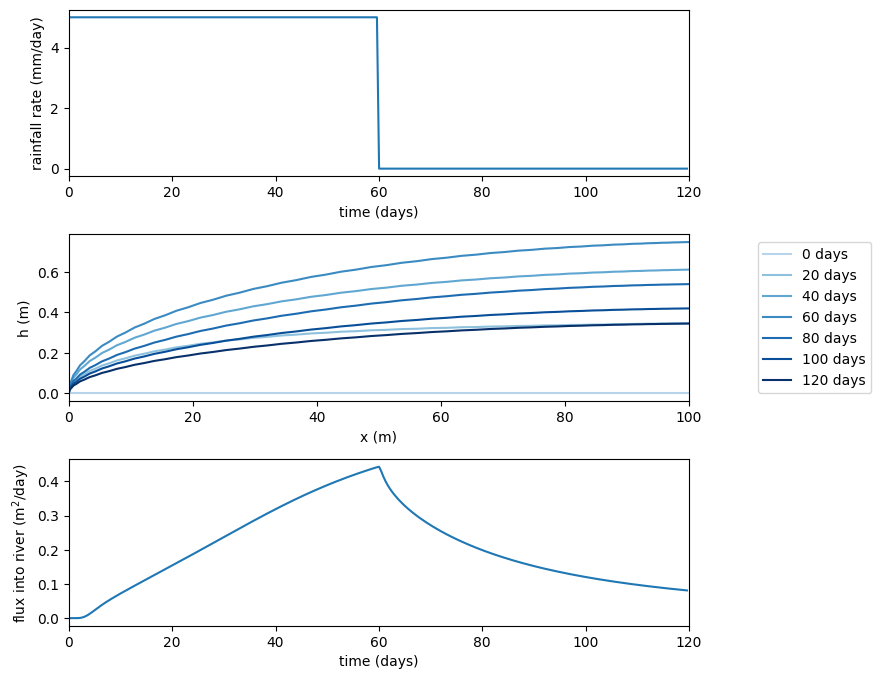

In [8]:
# create a figure and axes
fig = plt.figure(figsize=(8,8))

# Plot the rainfall rate
plt.subplot(3,1,1)
plt.plot(t_save / day, rainfall_rate(t_save) * 1e3 * day)
# Specify the axis limits and labels
plt.xlim(0, stop_sim_time / day)
plt.xlabel('time (days)')
plt.ylabel('rainfall rate (mm/day)')

# Plot the water table height at 20-day intervals
plt.subplot(3,1,2)
times_to_plot = [0, 20, 40, 60, 80, 100, 120] # days to include in plot
colors = plt.cm.Blues(np.linspace(0.3, 1.0, len(times_to_plot)))
x_plot = np.squeeze(x)
for i, t_plot in enumerate(times_to_plot):
    n = np.argmin(np.abs(t_save - t_plot * day))
    plt.plot(x_plot, np.squeeze(h_save[n]), color=colors[i], label='{0} days'.format(t_plot))
# Specify the axis limits and labels
plt.xlim(0, L)
plt.xlabel('x (m)')
plt.ylabel('h (m)')
plt.legend(loc='center left', bbox_to_anchor=(1.1, 0.5)) # add legend to the right of the plot

# Plot the flux into the river
plt.subplot(3,1,3)
plt.plot(t_save / day, QR_save * day)
# Specify the axis limits and labels
plt.xlim(0, stop_sim_time / day)
plt.xlabel('time (days)')
plt.ylabel('flux into river (m$^2$/day)')

plt.subplots_adjust(hspace=0.35) # add space between the panels


## 1.4 Student investigation
<a id='section1pt4'></a>
### Analytical comparison
In Fundamentals of Environmental Modelling we derived expressions for the flux into the river at early and late times. Compare these predictions with the simulation output and discuss any differences along with possible sources of error (~1 figure and ~3-4 sentences).

---


The groundwater model follows Darcy's law and conservation of water:

$$
q=-u_bh\frac{\partial h}{\partial x},
\qquad
\phi\frac{\partial h}{\partial t}
-u_b\frac{\partial}{\partial x}
\left(h\frac{\partial h}{\partial x}\right)=R(t),
$$

where $u_b=k\rho g/\mu$, $\phi$ is porosity, and the discharge into
the river per unit width is $Q_R=-q(0,t)$.

At early times, the initially empty aquifer fills approximately as
$h\sim R_0t/\phi$ away from the river. Balancing storage and drainage
gives an affected length $\ell\sim\sqrt{u_bR_0}\,t/\phi$, and hence

$$
Q_{R,\mathrm{early}}
\sim \frac{u_b^{1/2}R_0^{3/2}}{\phi}\,t.
$$

The plotted early-time reference is normalised at a selected
simulation time $t_{\mathrm{ref}}$:

$$
Q_{\mathrm{early,plot}}(t)
=Q_{\mathrm{sim}}(t_{\mathrm{ref}})
\frac{t}{t_{\mathrm{ref}}}.
$$

It therefore tests the approximately linear time dependence,
rather than independently predicting the discharge amplitude.

For late-time drainage, the lecture scaling gives

$$
h\sim\frac{\phi L^2}{u_bt},
\qquad
Q_{R,\mathrm{late}}\sim\frac{\phi^2L^3}{u_bt^2}.
$$

The plotted late-time estimate uses a unit dimensionless prefactor
and is shown after rainfall stops. Here, $t$ is measured from the
start of the simulation, not from rainfall cessation; this is a
long-time scaling estimate rather than an exact solution over the
whole drainage interval.



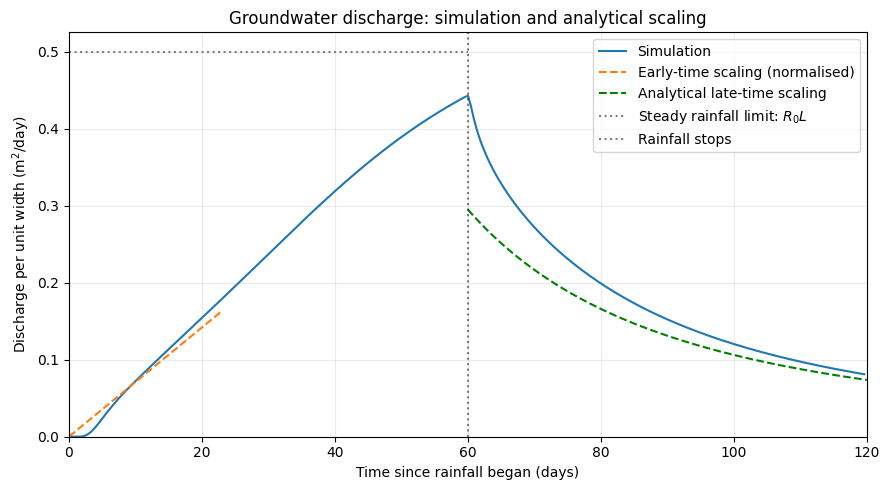

In [9]:
tc = phi * L / np.sqrt(ub * R0)

early_indices = np.flatnonzero((t_save > 0) & (t_save < T))
i_early = early_indices[
    np.argmin(np.abs(t_save[early_indices] - 0.2 * tc))
]

early = (t_save > 0) & (t_save <= min(0.5 * tc, T))
Q_early = QR_save[i_early] * t_save[early] / t_save[i_early]

t_late = np.linspace(60, 120, 600) * day
QR_late = (phi**2 * L**3) / (ub * t_late**2)

plt.figure(figsize=(9, 5))

plt.plot(
    t_save / day, QR_save * day,
    color="C0", label="Simulation"
)

plt.plot(
    t_save[early] / day, Q_early * day,
    "--", color="C1",
    label="Early-time scaling (normalised)"
)

plt.plot(
    t_late / day, QR_late * day,
    "--", color="green",
    label="Analytical late-time scaling"
)

plt.hlines(
    R0 * L * day, 0, T / day,
    colors="grey", linestyles=":",
    label=r"Steady rainfall limit: $R_0L$"
)

plt.axvline(
    T / day, color="black", linestyle=":",
    alpha=0.5, label="Rainfall stops"
)

plt.xlabel("Time since rainfall began (days)")
plt.ylabel(r"Discharge per unit width ($\mathrm{m^2/day}$)")
plt.title("Groundwater discharge: simulation and analytical scaling")
plt.xlim(0, 120)
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

After an initial transient, the simulated discharge increases
approximately linearly, consistent with the early-time scaling,
although normalisation means that amplitude agreement is not an
independent test of the theory.

The discharge reaches approximately $0.44\ \mathrm{m^2/day}$ when
rainfall stops at day 60, below the sustained-rainfall steady value
of $0.50\ \mathrm{m^2/day}$, indicating that steady state has not
yet been fully reached.

During drainage, the late-time estimate remains below the
simulation, but the difference decreases from approximately
$0.15\ \mathrm{m^2/day}$ at day 60 to approximately
$0.01\ \mathrm{m^2/day}$ at day 120, showing closer agreement at
later times without conclusively establishing the asymptotic
$t^{-2}$ law.

Possible sources of discrepancy include the unspecified
order-one prefactor in the scaling estimate, finite-time effects
before the asymptotic regime is reached, and numerical errors
associated with spatial resolution near the steep river boundary
and the finite time step.


---

### Qualitative behaviour
Explore different functional forms for the rainfall rate and the properties of the reservoir (e.g. size and permeability).  Include 2-3 figures to show the results of your parameter exploration and add 1-2 pargraphs to discuss and interpret your results.

---

### Experimental design

Three groups of experiments investigate  ***rainfall timing, permeability,
and aquifer length***. Each simulation starts with an empty aquifer and
uses the original groundwater equation and boundary conditions.


All three cases receive the same total rainfall,
$\int_0^T R(t)\,dt=R_0T=300$ mm, so the comparison isolates the
effect of rainfall timing.


### Exploration 1: Rainfall rate

Only the temporal form of rainfall is varied: constant, smooth
half-sinusoidal, and intermittent rainfall. Each case receives
300 mm over the first 60 days, with no rainfall thereafter, so
differences reflect rainfall timing rather than total rainfall.
Permeability ($k=10^{-10}\ \mathrm{m^2}$), aquifer length
($L=100\ \mathrm{m}$), and porosity ($\phi=0.3$) are held fixed.
All simulations start with an empty aquifer and use the same
governing equation, boundary conditions, 64 spatial grid points,
one-hour time step, and 120-day simulation duration.

Constant rainfall is 5 mm/day for 60 days.

Smooth rainfall follows
$R(t)=(\pi/2)R_0\sin(\pi t/T)$ for $0\leq t<T$, where
$R_0=5$ mm/day and $T=60$ days, giving a maximum of approximately
7.85 mm/day on day 30.

Intermittent rainfall alternates between
five days at 10 mm/day and five dry days, with the final wet
interval ending on day 55.

INFO:subsystems:Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 3.0e+01/s


Running: constant
2026-11-12 00:33:34,439 subsystems 0/1 INFO :: Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 3.0e+01/s


INFO:solvers:Simulation stop time reached.


2026-11-12 00:33:50,124 solvers 0/1 INFO :: Simulation stop time reached.


INFO:solvers:Simulation stop time reached.


2026-11-12 00:33:50,127 solvers 0/1 INFO :: Simulation stop time reached.


... (8 outputs left out)

INFO:solvers:Simulation stop time reached.


2026-11-12 00:34:04,403 solvers 0/1 INFO :: Simulation stop time reached.


INFO:solvers:Simulation stop time reached.


2026-11-12 00:34:04,407 solvers 0/1 INFO :: Simulation stop time reached.


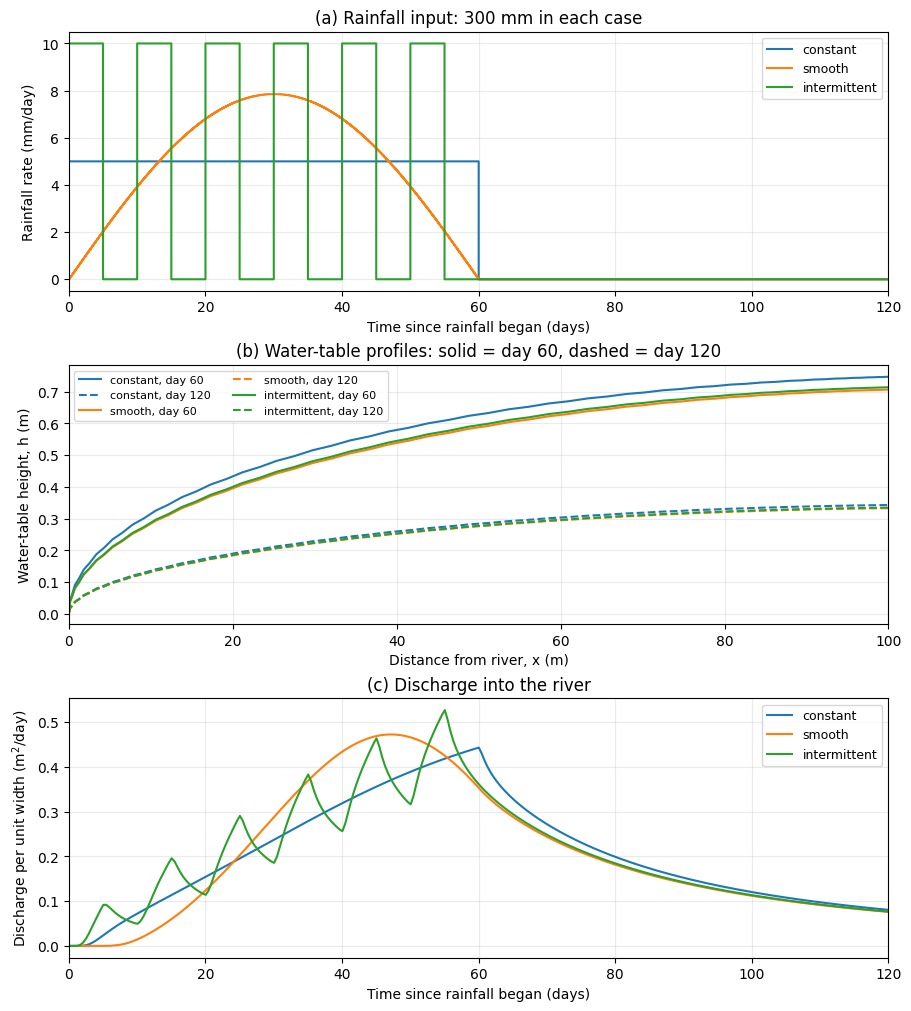

In [10]:
def rain_case(t, kind):
    d = 86400
    duration = 60 * d
    rate = 5e-3 / d
    t = np.asarray(t)
    if kind == 'constant':
        value = rate * np.ones_like(t, dtype=float)
    elif kind == 'smooth':
        value = (np.pi / 2) * rate * np.sin(np.pi * t / duration)
    elif kind == 'intermittent':
        value = np.where(t % (10 * d) < 5 * d, 2 * rate, 0.0)
    else:
        raise ValueError('Unknown rainfall case')
    return np.where((t >= 0) & (t < duration), value, 0.0)


def run_rainfall(kind):
    k, L, Nx = 1e-10, 100, 64
    phi = 0.3
    ub = k * 1000 * 9.81 / 1e-3
    R0 = 5e-3 / 86400
    nu = L * np.sqrt(ub * R0)
    timestep = 3600
    end = 120 * 86400

    coords = dedalus.CartesianCoordinates('x')
    dist = dedalus.Distributor(coords, dtype=np.float64)
    xbasis = dedalus.ChebyshevT(
        coords['x'], size=Nx, bounds=(0, L), dealias=3/2)
    h = dist.Field(name='h', bases=xbasis)
    tau_1 = dist.Field(name='tau_1')
    tau_2 = dist.Field(name='tau_2')
    R = dist.Field(name='R')
    R['g'] = float(rain_case(0, kind))

    lift_basis = xbasis.derivative_basis(1)
    lift = lambda a: dedalus.Lift(a, lift_basis, -1)
    dx = lambda a: dedalus.Differentiate(a, coords['x'])
    hx = dx(h) + lift(tau_1)

    problem = dedalus.IVP([h, tau_1, tau_2], namespace=locals())
    problem.add_equation(
        'phi*dt(h) - nu*dx(hx) + lift(tau_2) '
        '= R + ub*dx(h*hx) - nu*dx(hx)')
    problem.add_equation("h(x='left') = 0")
    problem.add_equation("hx(x='right') = 0")
    solver = problem.build_solver(dedalus.RK222)
    solver.stop_sim_time = end
    h['g'] = 0

    volume = phi * dedalus.integ(h)
    QR = (ub * h * hx)(x='left')
    h.change_scales(1)
    x_plot = np.copy(dist.local_grid(xbasis)).squeeze()
    times, fluxes, volumes = [0.0], [0.0], [0.0]
    profiles = [np.copy(h['g']).squeeze()]

    while solver.proceed:
        R['g'] = float(rain_case(solver.sim_time, kind))
        solver.step(timestep)
        if ((solver.iteration - 1) % 10 == 0
                or solver.sim_time == 60 * 86400
                or not solver.proceed):
            h.change_scales(1)
            times.append(solver.sim_time)
            profiles.append(np.copy(h['g']).squeeze())
            fluxes.append(QR.evaluate()['g'].item())
            volumes.append(volume.evaluate()['g'].item())

    result = dict(t=np.array(times), Q=np.array(fluxes),
                  V=np.array(volumes), x=x_plot, h=np.array(profiles),
                  k=k, L=L, kind=kind)
    if not (np.all(np.isfinite(result['Q']))
            and np.all(np.isfinite(result['V']))
            and np.all(np.isfinite(result['h']))):
        raise RuntimeError(f'Non-finite result: {kind}, k={k}, L={L}')
    return result


rain_results = {}
for name in ['constant', 'smooth', 'intermittent']:
    print('Running:', name)
    rain_results[name] = run_rainfall(name)

fig, axes = plt.subplots(3, 1, figsize=(9, 10), constrained_layout=True)
plot_times = np.arange(0, 120 * 86400 + 3600, 3600)
for j, (name, result) in enumerate(rain_results.items()):
    color = f'C{j}'
    axes[0].plot(plot_times / 86400,
                 rain_case(plot_times, name) * 86400 * 1000,
                 color=color, label=name, drawstyle='steps-post')
    for target_day, style in [(60, '-'), (120, '--')]:
        index = np.argmin(np.abs(result['t'] - target_day * 86400))
        axes[1].plot(result['x'], result['h'][index],
                     color=color, linestyle=style,
                     label=f'{name}, day {target_day}')
    axes[2].plot(result['t'] / 86400, result['Q'] * 86400,
                 color=color, label=name)

axes[0].set(title='(a) Rainfall input: 300 mm in each case',
            xlabel='Time since rainfall began (days)',
            ylabel='Rainfall rate (mm/day)', xlim=(0, 120))
axes[1].set(title='(b) Water-table profiles: solid = day 60, dashed = day 120',
            xlabel='Distance from river, x (m)',
            ylabel='Water-table height, h (m)', xlim=(0, 100))
axes[2].set(title='(c) Discharge into the river',
            xlabel='Time since rainfall began (days)',
            ylabel=r'Discharge per unit width ($\mathrm{m^2/day}$)',
            xlim=(0, 120))
for ax in axes:
    ax.grid(alpha=0.25)
axes[0].legend(loc='upper right', fontsize=9)
axes[1].legend(loc='upper left', fontsize=8, ncol=2)
axes[2].legend(loc='upper right', fontsize=9)
plt.show()


### Discussion 1:
Although all three scenarios receive the same total rainfall,
their discharge histories differ substantially. Constant rainfall
produces a gradual increase to approximately
$0.44\ \mathrm{m^2/day}$ at day 60, whereas smooth rainfall produces
a broader peak of approximately $0.47\ \mathrm{m^2/day}$ around
day 47, about 17 days after its rainfall maximum. This delay
reflects aquifer storage and the time required for groundwater
to drain towards the river. Intermittent rainfall produces
successive discharge peaks, reaching approximately
$0.53\ \mathrm{m^2/day}$ near day 55, while discharge remains
positive during dry intervals because previously stored water
continues to drain. The increasing peaks across successive wet
periods indicate that the aquifer does not empty between events.
Once rainfall has ceased in all cases, discharge declines and
the curves approach one another, although the constant-rainfall
case remains slightly higher over the plotted drainage period.
Thus, rainfall timing affects both peak discharge and its timing,
even when cumulative rainfall is unchanged.

The water-table height increases with distance from the river and
flattens towards the drainage divide, consistent with the imposed
boundary conditions. At day 60, constant rainfall produces the
highest water table, reaching approximately 0.75 m at $x=100$ m,
compared with about 0.71–0.72 m for the other two scenarios,
indicating greater remaining storage despite equal cumulative rainfall.
This is consistent with continued rainfall up to day 60 in the
constant case, whereas smooth rainfall gradually weakens and the
final intermittent wet period ends on day 55.
By day 120, all three profiles have fallen substantially and nearly
coincide, with maximum heights around 0.34 m, showing that differences
associated with rainfall timing diminish during subsequent drainage.

---

### Exploration 2: Permeability

Only aquifer permeability is varied, using
$k=5\times10^{-11}$, $10^{-10}$, and
$2\times10^{-10}\ \mathrm{m^2}$.
Rainfall is fixed at 5 mm/day for the first 60 days and zero
thereafter, giving 300 mm in each case.
Aquifer length ($L=100\ \mathrm{m}$), porosity ($\phi=0.3$),
water density, viscosity, and gravitational acceleration are
held constant.

All simulations start with an empty aquifer and use the same
governing equation, boundary conditions, 64 spatial grid points,
one-hour time step, and 120-day simulation duration.
The buoyancy velocity $u_b=k\rho g/\mu$ and the associated
numerical splitting coefficient are recalculated for each
permeability. Both river discharge and stored water per unit
width, $V=\phi\int_0^L h\,dx$, are compared.

INFO:subsystems:Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 1.6e+01/s


Running k = 5.0e-11 m²
2026-11-12 01:38:08,613 subsystems 0/1 INFO :: Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 1.6e+01/s


INFO:solvers:Simulation stop time reached.


2026-11-12 01:38:16,562 solvers 0/1 INFO :: Simulation stop time reached.


INFO:solvers:Simulation stop time reached.


2026-11-12 01:38:16,566 solvers 0/1 INFO :: Simulation stop time reached.


... (8 outputs left out)

INFO:solvers:Simulation stop time reached.


2026-11-12 01:38:31,785 solvers 0/1 INFO :: Simulation stop time reached.


INFO:solvers:Simulation stop time reached.


2026-11-12 01:38:31,789 solvers 0/1 INFO :: Simulation stop time reached.
All three permeability simulations completed.


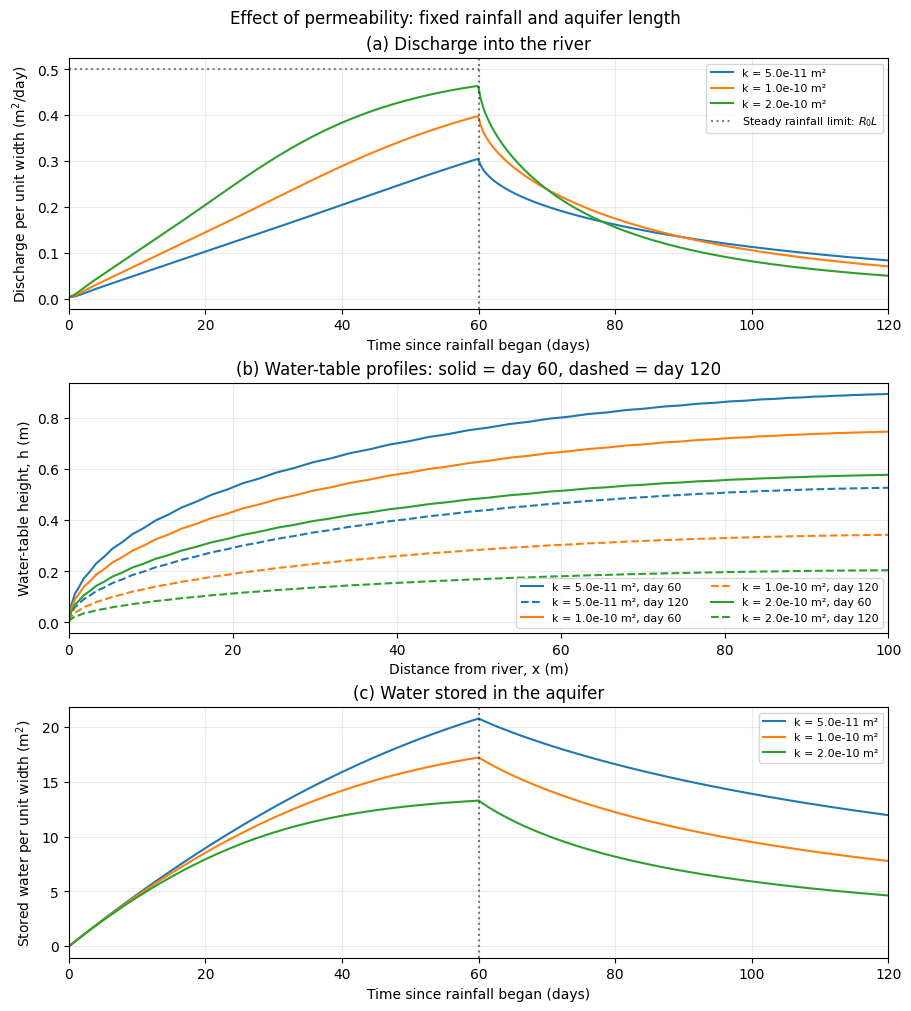

In [32]:
def run_permeability (k):
    L = 100
    Nx = 64
    timestep = 3600
    phi = 0.3
    R0 = 5e-3 / 86400
    T = 60 * 86400
    end_time = 120 * 86400

    ub = k * 1000 * 9.81 / 1e-3
    nu = L * np.sqrt(ub * R0)

    coords = dedalus.CartesianCoordinates("x")
    dist = dedalus.Distributor(coords, dtype=np.float64)
    xbasis = dedalus.ChebyshevT(
        coords["x"], size=Nx, bounds=(0, L), dealias=3/2
    )

    h = dist.Field(name="h", bases=xbasis)
    tau_1 = dist.Field(name="tau_1")
    tau_2 = dist.Field(name="tau_2")
    R = dist.Field(name="R")
    R["g"] = R0

    lift_basis = xbasis.derivative_basis(1)
    lift = lambda a: dedalus.Lift(a, lift_basis, -1)
    dx = lambda a: dedalus.Differentiate(a, coords["x"])
    hx = dx(h) + lift(tau_1)

    problem = dedalus.IVP([h, tau_1, tau_2], namespace=locals())
    problem.add_equation(
        "phi*dt(h) - nu*dx(hx) + lift(tau_2) "
        "= R + ub*dx(h*hx) - nu*dx(hx)"
    )
    problem.add_equation("h(x='left') = 0")
    problem.add_equation("hx(x='right') = 0")

    solver = problem.build_solver(dedalus.RK222)
    solver.stop_sim_time = end_time
    h["g"] = 0

    QR = (ub * h * hx)(x="left")
    volume = phi * dedalus.integ(h)

    h.change_scales(1)
    x_grid = np.copy(dist.local_grid(xbasis)).squeeze()

    times = [0.0]
    fluxes = [0.0]
    volumes = [0.0]
    profiles = [np.copy(h["g"]).squeeze()]

    while solver.proceed:
        R["g"] = R0 if solver.sim_time < T else 0.0
        solver.step(timestep)

        if (
            (solver.iteration - 1) % 10 == 0
            or solver.sim_time == T
            or not solver.proceed
        ):
            h.change_scales(1)
            times.append(solver.sim_time)
            profiles.append(np.copy(h["g"]).squeeze())
            fluxes.append(QR.evaluate()["g"].item())
            volumes.append(volume.evaluate()["g"].item())

    result = {
        "t": np.array(times),
        "Q": np.array(fluxes),
        "V": np.array(volumes),
        "x": x_grid,
        "h": np.array(profiles)
    }

    for key in ["Q", "V", "h"]:
        if not np.all(np.isfinite(result[key])):
            raise RuntimeError(f"Non-finite {key} for k = {k}")

    times = result["t"]
    cumulative_input = (
        R0 * L * np.minimum(times, T)
    )

    result["t_Q"] = 0.5 * (times[:-1] + times[1:])
    result["Q_balance"] = (
        np.diff(cumulative_input) - np.diff(result["V"])
    ) / np.diff(times)

    return result


k_results = {}

for kval in [0.5e-10, 1e-10, 2e-10]:
    print(f"Running k = {kval:.1e} m²")
    k_results[kval] = run_permeability(kval)

print("All three permeability simulations completed.")


fig, axes = plt.subplots(
    3, 1, figsize=(9, 10), constrained_layout=True
)

for j, (kval, result) in enumerate(k_results.items()):
    color = f"C{j}"
    label = f"k = {kval:.1e} m²"

    axes[0].plot(
        result["t_Q"] / 86400,
        result["Q_balance"] * 86400,
        color=color, label=label
    )

    for target_day, style in [(60, "-"), (120, "--")]:
        index = np.argmin(
            np.abs(result["t"] - target_day * 86400)
        )
        axes[1].plot(
            result["x"],
            result["h"][index],
            color=color,
            linestyle=style,
            label=f"{label}, day {target_day}"
        )

    axes[2].plot(
        result["t"] / 86400,
        result["V"],
        color=color, label=label
    )

axes[0].hlines(
    0.5, 0, 60,
    colors="grey", linestyles=":",
    label=r"Steady rainfall limit: $R_0L$"
)

axes[0].set(
    title="(a) Discharge into the river",
    ylabel=r"Discharge per unit width ($\mathrm{m^2/day}$)"
)

axes[1].set(
    title="(b) Water-table profiles: solid = day 60, dashed = day 120",
    xlabel="Distance from river, x (m)",
    ylabel="Water-table height, h (m)",
    xlim=(0, 100)
)

axes[2].set(
    title="(c) Water stored in the aquifer",
    ylabel=r"Stored water per unit width ($\mathrm{m^2}$)"
)

for i in [0, 2]:
    axes[i].set(
        xlabel="Time since rainfall began (days)",
        xlim=(0, 120)
    )
    axes[i].axvline(
        60, color="black", linestyle=":", alpha=0.5
    )

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

axes[1].legend(fontsize=8, ncol=2)

fig.suptitle(
    "Effect of permeability: fixed rainfall and aquifer length"
)
plt.show()

### Discussion 2:
Increasing permeability produces a faster discharge response during
rainfall: near day 60, discharge reaches approximately 0.34, 0.44,
and 0.52 m²/day for the low, intermediate, and high permeability
cases, respectively. This is consistent with Darcy's law, since
$u_b=k\rho g/\mu$ increases with permeability, allowing more rapid
drainage for a given water-table profile. Consequently, higher
permeability produces lower water tables and less stored water:
at day 60, storage is approximately 21, 17, and 13 m² per unit
width, respectively. After rainfall stops, the high-permeability
aquifer drains more rapidly, whereas the low-permeability aquifer
retains more water and eventually sustains the larger discharge;
the day-120 water-table profiles and storage curves support this
interpretation. These trends are consistent with the characteristic
response time $t_c=\phi L/\sqrt{u_bR_0}\propto k^{-1/2}$.
Permeability changes the response timescale and storage, but not
the sustained-rainfall steady discharge $R_0L=0.50$ m²/day.
The slight overshoot of this value in the high-permeability
simulation warrants a numerical accuracy check rather than being
interpreted as a higher theoretical steady discharge.

---

### Exploration 3: Aquifer length

Aquifer length is varied between $L=50$, $100$, and $200$ m,
with permeability fixed at $k=10^{-10}\ \mathrm{m^2}$.
Rainfall remains 5 mm/day for 60 days, followed by no rainfall;
all other physical and numerical settings are unchanged.

The no-flow boundary moves to the corresponding $x=L$.
Although rainfall depth is identical, total input per unit river
width increases with length, giving steady-rainfall discharge
limits $R_0L=0.25$, $0.50$, and $1.00\ \mathrm{m^2/day}$.
With 64 grid points retained, physical grid spacing also changes
with domain length.


INFO:subsystems:Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 3.0e+01/s


Running L = 50 m
2026-11-12 01:45:16,758 subsystems 0/1 INFO :: Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 3.0e+01/s


INFO:solvers:Simulation stop time reached.


2026-11-12 01:45:24,661 solvers 0/1 INFO :: Simulation stop time reached.


INFO:solvers:Simulation stop time reached.


2026-11-12 01:45:24,665 solvers 0/1 INFO :: Simulation stop time reached.


... (8 outputs left out)

INFO:solvers:Simulation stop time reached.


2026-11-12 01:45:39,183 solvers 0/1 INFO :: Simulation stop time reached.


INFO:solvers:Simulation stop time reached.


2026-11-12 01:45:39,188 solvers 0/1 INFO :: Simulation stop time reached.
All three length simulations completed.


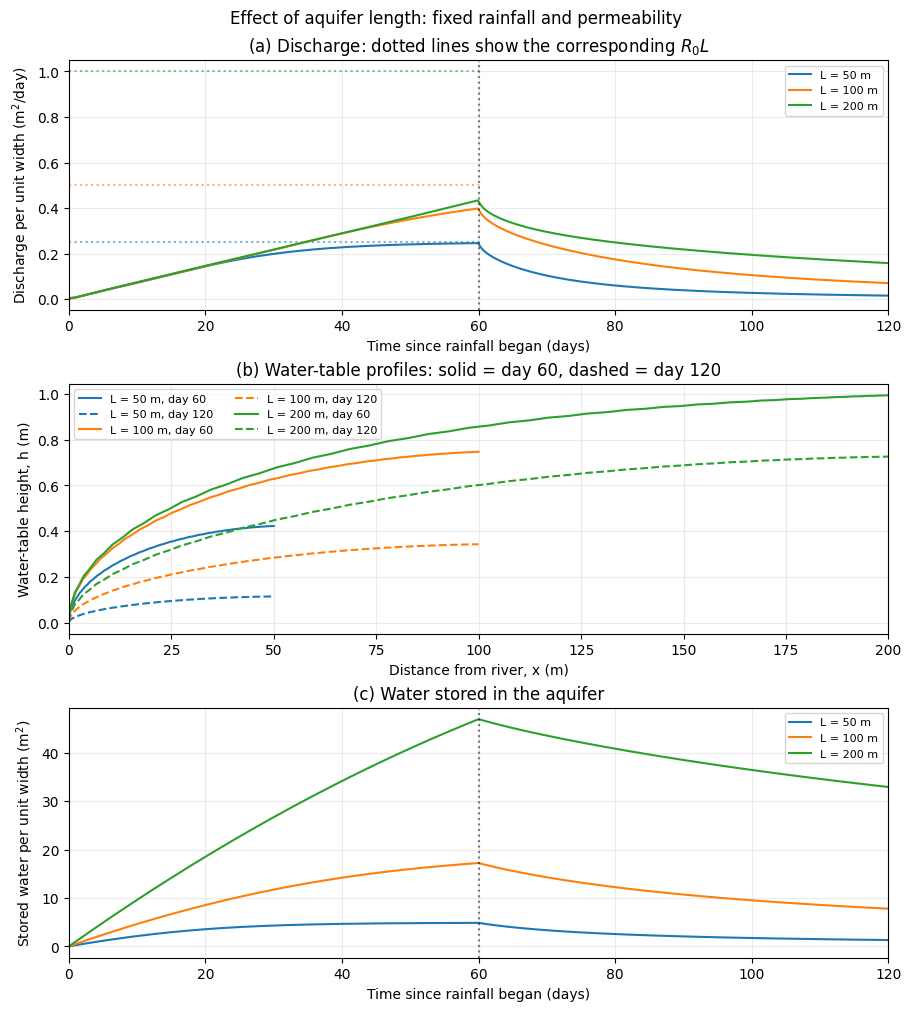

In [36]:
def run_length(L):
    # Only aquifer length changes between simulations
    k = 1e-10
    phi = 0.3
    Nx = 64
    R0 = 5e-3 / 86400
    T = 60 * 86400
    timestep = 3600
    end_time = 120 * 86400

    ub = k * 1000 * 9.81 / 1e-3
    nu = L * np.sqrt(ub * R0)

    # Rebuild the spatial domain for each length
    coords = dedalus.CartesianCoordinates("x")
    dist = dedalus.Distributor(coords, dtype=np.float64)
    xbasis = dedalus.ChebyshevT(
        coords["x"], size=Nx, bounds=(0, L), dealias=3/2
    )

    h = dist.Field(name="h", bases=xbasis)
    tau_1 = dist.Field(name="tau_1")
    tau_2 = dist.Field(name="tau_2")
    R = dist.Field(name="R")
    R["g"] = R0

    lift_basis = xbasis.derivative_basis(1)
    lift = lambda a: dedalus.Lift(a, lift_basis, -1)
    dx = lambda a: dedalus.Differentiate(a, coords["x"])
    hx = dx(h) + lift(tau_1)

    # Original equation and boundary conditions
    problem = dedalus.IVP([h, tau_1, tau_2], namespace=locals())
    problem.add_equation(
        "phi*dt(h) - nu*dx(hx) + lift(tau_2) "
        "= R + ub*dx(h*hx) - nu*dx(hx)"
    )
    problem.add_equation("h(x='left') = 0")
    problem.add_equation("hx(x='right') = 0")

    solver = problem.build_solver(dedalus.RK222)
    solver.stop_sim_time = end_time
    h["g"] = 0

    QR = (ub * h * hx)(x="left")
    volume = phi * dedalus.integ(h)

    h.change_scales(1)
    x_grid = np.copy(dist.local_grid(xbasis)).squeeze()

    times = [0.0]
    fluxes = [0.0]
    volumes = [0.0]
    profiles = [np.copy(h["g"]).squeeze()]

    while solver.proceed:
        R["g"] = R0 if solver.sim_time < T else 0.0
        solver.step(timestep)

        if (
            (solver.iteration - 1) % 10 == 0
            or solver.sim_time == T
            or not solver.proceed
        ):
            h.change_scales(1)
            times.append(solver.sim_time)
            profiles.append(np.copy(h["g"]).squeeze())
            fluxes.append(QR.evaluate()["g"].item())
            volumes.append(volume.evaluate()["g"].item())

    result = {
        "t": np.array(times),
        "Q": np.array(fluxes),
        "V": np.array(volumes),
        "x": x_grid,
        "h": np.array(profiles)
    }

    for key in ["Q", "V", "h"]:
        if not np.all(np.isfinite(result[key])):
            raise RuntimeError(f"Non-finite {key} for L = {L}")

    times = result["t"]
    cumulative_input = (
        R0 * L * np.minimum(times, T)
    )

    result["t_Q"] = 0.5 * (times[:-1] + times[1:])
    result["Q_balance"] = (
        np.diff(cumulative_input) - np.diff(result["V"])
    ) / np.diff(times)

    return result


# Three independent simulations
L_results = {}

for length in [50, 100, 200]:
    print(f"Running L = {length} m")
    L_results[length] = run_length(length)

print("All three length simulations completed.")


# Three panels: discharge, water-table profiles, and storage
fig, axes = plt.subplots(
    3, 1, figsize=(9, 10), constrained_layout=True
)

for j, (length, result) in enumerate(L_results.items()):
    color = f"C{j}"
    label = f"L = {length} m"

    # (a) Discharge and the corresponding steady-rainfall limit
    axes[0].plot(
         result["t_Q"] / 86400,
        result["Q_balance"] * 86400,
        color=color, label=label
    )

    axes[0].hlines(
        0.005 * length, 0, 60,
        colors=color, linestyles=":", alpha=0.6
    )

    # (b) Water-table profiles on each physical domain
    for target_day, style in [(60, "-"), (120, "--")]:
        index = np.argmin(
            np.abs(result["t"] - target_day * 86400)
        )
        axes[1].plot(
            result["x"],
            result["h"][index],
            color=color,
            linestyle=style,
            label=f"{label}, day {target_day}"
        )

    # (c) Stored water
    axes[2].plot(
        result["t"] / 86400,
        result["V"],
        color=color, label=label
    )

axes[0].set(
    title=r"(a) Discharge: dotted lines show the corresponding $R_0L$",
    ylabel=r"Discharge per unit width ($\mathrm{m^2/day}$)"
)

axes[1].set(
    title="(b) Water-table profiles: solid = day 60, dashed = day 120",
    xlabel="Distance from river, x (m)",
    ylabel="Water-table height, h (m)",
    xlim=(0, 200)
)

axes[2].set(
    title="(c) Water stored in the aquifer",
    ylabel=r"Stored water per unit width ($\mathrm{m^2}$)"
)

for i in [0, 2]:
    axes[i].set(
        xlabel="Time since rainfall began (days)",
        xlim=(0, 120)
    )
    axes[i].axvline(
        60, color="black", linestyle=":", alpha=0.5
    )

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

axes[1].legend(fontsize=8, ncol=2)

fig.suptitle(
    "Effect of aquifer length: fixed rainfall and permeability"
)
plt.show()

### Discussion 3:
The discharge curves are initially similar, consistent with the
early-time scaling being independent of aquifer length while
drainage is primarily influenced by conditions near the river.
Later, the 50 m aquifer levels off earlier, whereas discharge from
the longer aquifers continues to increase. At day 60, discharge
is approximately 0.28, 0.44, and 0.48 m²/day for lengths of 50,
100, and 200 m, respectively. Although the 200 m aquifer has the
largest discharge, this is less than half its sustained-rainfall
steady value of 1.00 m²/day, indicating that it remains far from
steady state. This behaviour is consistent with the response
timescale $t_c=\phi L/\sqrt{u_bR_0}$ increasing with length.
The 50 m simulation slightly exceeds its theoretical steady
value of 0.25 m²/day, which warrants a numerical accuracy check
rather than being interpreted as a different steady-state limit.

The water-table profiles and storage curves show greater water
retention in longer aquifers. At day 60, water-table heights at
the respective drainage divides are approximately 0.43, 0.75,
and 1.00 m, while stored water is approximately 5, 17, and
47 m² per unit width. These differences reflect both the larger
rainfall input $R_0L$ and the longer drainage response time;
equal rainfall depth does not imply equal total water input.
By day 120, the corresponding maximum water-table heights have
fallen to approximately 0.12, 0.34, and 0.73 m, with around
1.5, 8, and 33 m² of water remaining in storage. Thus, the
shortest aquifer loses a greater fraction of its stored water
during the post-rainfall period, while the longest retains a
higher water table and sustains a larger discharge for longer.

---


### Conclusion:
Overall, the experiments show that groundwater discharge depends on
how rainfall is distributed in time and how efficiently the aquifer
stores and releases water. With the same total rainfall of 300 mm,
intermittent rainfall produces repeated discharge peaks and the
largest peak, whereas smooth rainfall produces a broader peak delayed
relative to the rainfall maximum. Increasing permeability accelerates
drainage, producing greater discharge during rainfall but lower water
tables and less remaining storage; after sufficient drainage, the
less permeable aquifer sustains the larger discharge. Increasing
aquifer length increases rainfall input and storage, but also lengthens
the response time, so a larger absolute discharge does not imply a
closer approach to steady state. Together, these behaviours are
consistent with $t_c\propto L/\sqrt{k}$: short, permeable aquifers
respond quickly, while long, less permeable aquifers retain water
and prolong river flow after rainfall stops.

---






## 2. Transport of pollution in a river

Advection/diffusion equations are a common way to model the material transport in many physical systems. In this section we will model the transport and dilution of a pollutants added to a river.

For simplicity, we will model the river as a rectangular channel, and we will neglect depth variations. Let $x$ be the coordinate along the length of the river, and $y$ be the cross-stream coordinate. We will model the river current as

$$ u(y) = U_0\left(1-\frac{(y-w/2)^2}{(w/2)^2}\right) $$

where $w$ is the width of the river and $U_0$ is the maximum current speed which occurs at the center of the river (the $y$-coordinate will run from 0 to $w$).

Since we want to know how the pollution levels vary in time, we will solve the time-dependent advection/diffusion equation. We will model the addition of pollution by adding a spatially-dependent source term to the right hand side of the equation governing pollutant concentration:

$$ \frac{\partial c}{\partial t} + u(y)\frac{\partial c}{\partial x} = \kappa \nabla^2 c + S(x,y) $$

where $\nabla^2=(\partial_x^2 + \partial_y^2)$ is the Laplacian operator for diffusion in 2D Cartesian coordinates, and $S$ is the source term.

### 2.1 Dedalus script

The script below solves the time-dependent advection/diffusion equation with a source term.

In [13]:
"""
Script to solve the time-dependent advection/diffusion equation
"""

import numpy as np
import matplotlib.pyplot as plt
import dedalus.public as dedalus
import logging
logger = logging.getLogger(__name__)

# Set parameters
U0 = 0.1 # maximum current speed in m/s
w = 10 # width of the river in m
L = 50 # length of the river section to simulate
kappa = 1e-2 # diffusivity in m^2/s
S0 = 1 # amplitude of the pollution source term
S_w = 1 # width of the source term in m
S_x = 10 # center of the forcing in x
S_y = 0 # center of the forcing in y
S_t = 1 # forcing timescale

# Numerical parameters
Nx = 256 # number of gridoints in x
Ny = 32 # number of gridpoints in y
stop_sim_time=1500 # end time in seconds
timestep = (L/Nx)/U0 # timestep in seconds, calculated from the CFL number

import numpy as np
import dedalus.public as dedalus
import logging
logger = logging.getLogger(__name__)

# Bases and coordinates
coords = dedalus.CartesianCoordinates('x', 'y')
dist = dedalus.Distributor(coords, dtype=np.float64)
xbasis = dedalus.RealFourier(coords['x'], size=Nx, bounds=(0, L), dealias=3/2)
ybasis = dedalus.ChebyshevT(coords['y'], size=Ny, bounds=(0, w), dealias=3/2)
x, y = dist.local_grids(xbasis, ybasis)
ex, ey = coords.unit_vector_fields(dist) # x and y unit vectors

# Fields
c = dist.Field(name='c', bases=(xbasis,ybasis))
u = dist.Field(name='u', bases=(xbasis,ybasis))
tau_1 = dist.Field(name='tau_1', bases=xbasis)
tau_2 = dist.Field(name='tau_2', bases=xbasis)

# Specify the velocity field
u['g'] = U0 * (1- (y - w/2)**2.0/(w/2)**2.0) # parabolic velocity profile

# Substitutions
lift_basis = ybasis.derivative_basis(1)
lift = lambda A: dedalus.Lift(A, lift_basis, -1)
grad_c = dedalus.grad(c) + ey*lift(tau_1)
dx = lambda A: dedalus.Differentiate(A, coords['x'])

S = dist.Field(name='u', bases=(xbasis,ybasis))
S['g'] = S0*np.exp(-(x-S_x)**2.0/S_w**2.0-(y-S_y)**2.0/S_w**2.0)

# Problem
problem = dedalus.IVP([c, tau_1, tau_2], namespace=locals())
problem.add_equation("dt(c) + u*dx(c) - kappa*div(grad_c) + lift(tau_2) = S/S_t")
problem.add_equation("c(y=0) = 0")
problem.add_equation("c(y=w) = 0")

# Now, set the solver
solver = problem.build_solver(dedalus.RK222)
solver.stop_sim_time = stop_sim_time

# Create an array to periodically save the concentration field for plotting later
c.change_scales(1)
c_save = [np.copy(c['g'])];

t_save = [solver.sim_time]; # Save the initial condition and the initial time
# Main loop
try:
    logger.info('Starting main loop')
    while solver.proceed:
        solver.step(timestep)
        if (solver.iteration-1) % 10 == 0:
            logger.info('Iteration=%i, Time=%e, dt=%e' %(solver.iteration, solver.sim_time, timestep))
            c.change_scales(1)
            c_save.append(np.copy(c['g']))
            t_save.append(solver.sim_time)
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

# Convert the variables to numpy arrays for allow array slicing
c_save = np.array(c_save)

INFO:subsystems:Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 5.0e+00/s


2026-11-12 00:34:49,719 subsystems 0/1 INFO :: Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 5.0e+00/s


INFO:__main__:Starting main loop


2026-11-12 00:34:49,726 __main__ 0/1 INFO :: Starting main loop


INFO:__main__:Iteration=1, Time=1.953125e+00, dt=1.953125e+00


2026-11-12 00:34:50,374 __main__ 0/1 INFO :: Iteration=1, Time=1.953125e+00, dt=1.953125e+00


... (164 outputs left out)

INFO:solvers:CPU time (iter 10-end): 0.0008026 cpu-hr


2026-11-12 00:34:53,294 solvers 0/1 INFO :: CPU time (iter 10-end): 0.0008026 cpu-hr


INFO:solvers:Speed: 4.549e+06 mode-stages/cpu-sec


2026-11-12 00:34:53,295 solvers 0/1 INFO :: Speed: 4.549e+06 mode-stages/cpu-sec


## 2.2 Visualization

The script below makes a movie of the results from the saved variables. To run this, you need to have ffmpeg installed.  If you don't already have it installed, you can install ffmpeg with the command:

`conda install -c conda-forge ffmpeg`

INFO:matplotlib.animation:Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


2026-11-12 00:34:53,524 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


INFO:matplotlib.animation:MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 600x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmp_y3w96w8/temp.m4v


2026-11-12 00:34:53,526 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 600x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmp_y3w96w8/temp.m4v


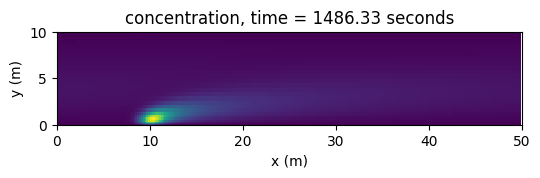

In [14]:
# create a figure and axes
fig = plt.figure(figsize=(6,6))

# Create arrays with the latitude and longitude coordinates for plotting using pcolor
from dedalus.extras import plot_tools
(X, Y) = plot_tools.quad_mesh(np.squeeze(x), np.squeeze(y))

# Define an animation function
def drawframe(n):
    plt.clf()
    concentration = plt.pcolor(X, Y, c_save[n,:,:].T)
    # Specify the axis limits and labels
    plt.axis('square')
    plt.xlim(0, L)
    plt.ylim(0, w)
    plt.xlabel('x (m)')
    plt.ylabel('y (m)')
    plt.title('concentration, time = {0:.2f} seconds'.format(t_save[n]))
    return (concentration,)

from matplotlib import animation
# blit=True re-draws only the parts that have changed.
anim = animation.FuncAnimation(fig, drawframe, frames=len(t_save), interval=40, blit=True)

from IPython.display import HTML
HTML(anim.to_html5_video())

## 2.3 Student investigation
<a id='section2pt3'></a>
### Advective/diffusive timescales
In the boxes below, plot the pollution concentration at a few points as a function of time. Then vary the maximum flow speed and the diffusivity and explore how the pollution levels depend on these parameters. Using dimensional analysis, estimate the time needed for the pollution to reach the opposite side of the river. How far downstream of the source do you expect this to happen (assuming that the domain in the x-direction is infinite).

---


### Concentration of selected locations
Concentration histories are sampled near $(x,y)=(20,1)$,
$(20,5)$, and $(20,9)$ m, representing locations near the
source-side bank, at the river centre, and near the opposite bank.
The same downstream coordinate is used to compare cross-stream
transport. The nearest available grid points are selected, and
their actual coordinates are shown in the legend.

All parameters retain their baseline values from Section 2.1,
including $U_0=0.1\ \mathrm{m/s}$ and
$\kappa=0.01\ \mathrm{m^2/s}$. Sampling points lie inside the
channel because concentration is fixed at zero at both banks.

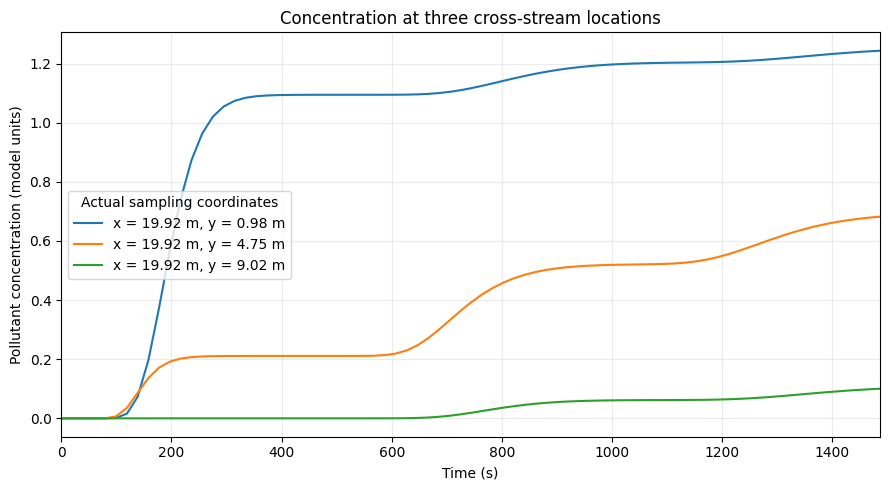

In [15]:
x_points = np.asarray(x).reshape(-1)
y_points = np.asarray(y).reshape(-1)
t_points = np.asarray(t_save)

assert c_save.shape == (
    len(t_points), len(x_points), len(y_points)
), "Check that x, y, t_save and c_save are from the river model."

sample_points = [(20, 1), (20, 5), (20, 9)]
point_series = {}

fig, ax = plt.subplots(figsize=(9, 5))

for x_target, y_target in sample_points:
    ix = np.argmin(np.abs(x_points - x_target))
    iy = np.argmin(np.abs(y_points - y_target))

    concentration = c_save[:, ix, iy]
    point_series[(x_target, y_target)] = concentration.copy()

    ax.plot(
        t_points,
        concentration,
        label=(
            f"x = {x_points[ix]:.2f} m, "
            f"y = {y_points[iy]:.2f} m"
        )
    )

ax.set(
    xlabel="Time (s)",
    ylabel="Pollutant concentration (model units)",
    title="Concentration at three cross-stream locations",
    xlim=(0, t_points[-1])
)

ax.legend(title="Actual sampling coordinates")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

---

### Exploration 1: change the maximum flow speed


Only the maximum flow speed is varied, using
$U_0=0.05$, $0.10$, and $0.20\ \mathrm{m/s}$.
Diffusivity is fixed at $\kappa=0.01\ \mathrm{m^2/s}$.
River length ($L=50$ m), width ($w=10$ m), and the continuously
active Gaussian pollution source remain unchanged from Section 2.1.

Each simulation starts with zero concentration and uses the same
periodic boundary condition in $x$, zero-concentration conditions
at both banks, and a $256\times32$ spatial grid.
All cases run for 1500 s with a common nominal time step of
$\Delta t=(L/N_x)/0.20=0.9765625$ s; the final step is shortened
to end at exactly 1500 s.

Concentration histories are compared at the nearest grid points
to $(20,1)$, $(20,5)$, and $(20,9)$ m. The actual sampling
coordinates are displayed in the subplot titles.
Changing $U_0$ also changes the circulation time through the
periodic domain, which must be considered when interpreting
the concentration histories.

Running U0 = 0.05


INFO:subsystems:Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 4.8e+00/s


2026-11-12 00:35:10,905 subsystems 0/1 INFO :: Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 4.8e+00/s


INFO:solvers:Simulation stop time reached.


2026-11-12 00:35:14,508 solvers 0/1 INFO :: Simulation stop time reached.


INFO:solvers:Simulation stop time reached.


... (9 outputs left out)

INFO:solvers:Simulation stop time reached.


2026-11-12 00:35:23,420 solvers 0/1 INFO :: Simulation stop time reached.


INFO:solvers:Simulation stop time reached.


2026-11-12 00:35:23,423 solvers 0/1 INFO :: Simulation stop time reached.
All three simulations completed.


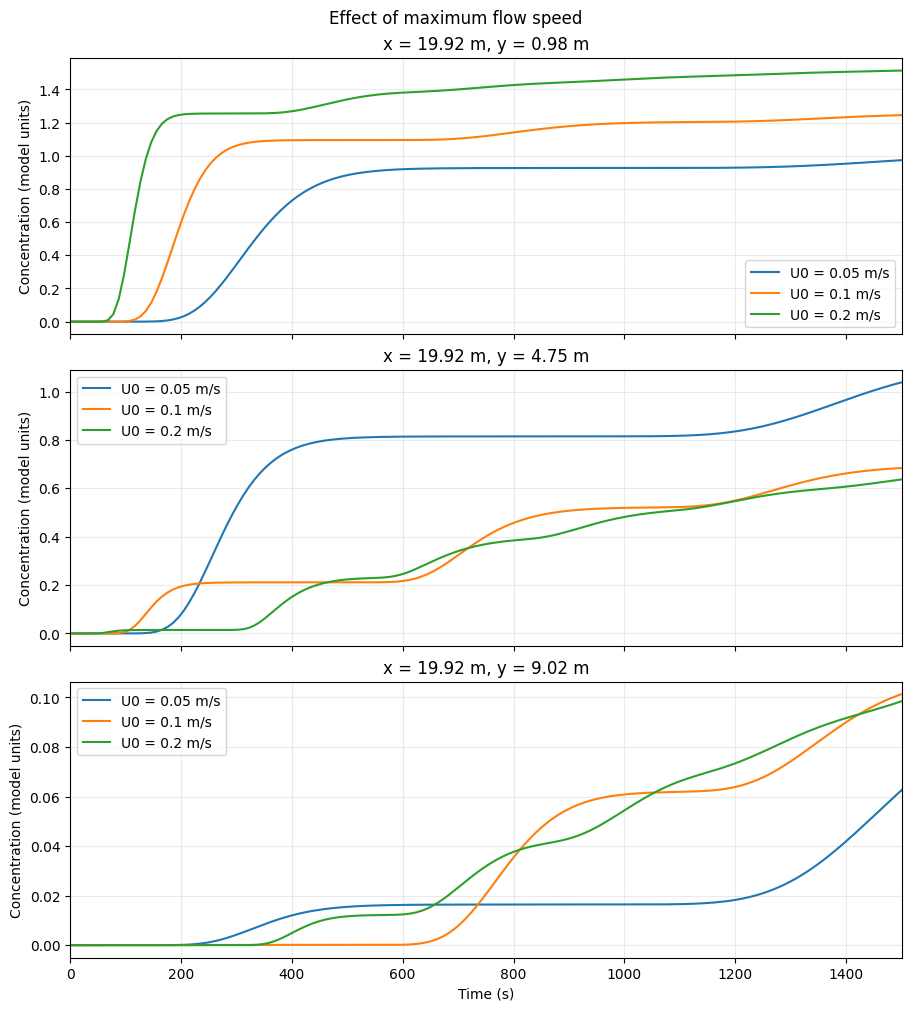

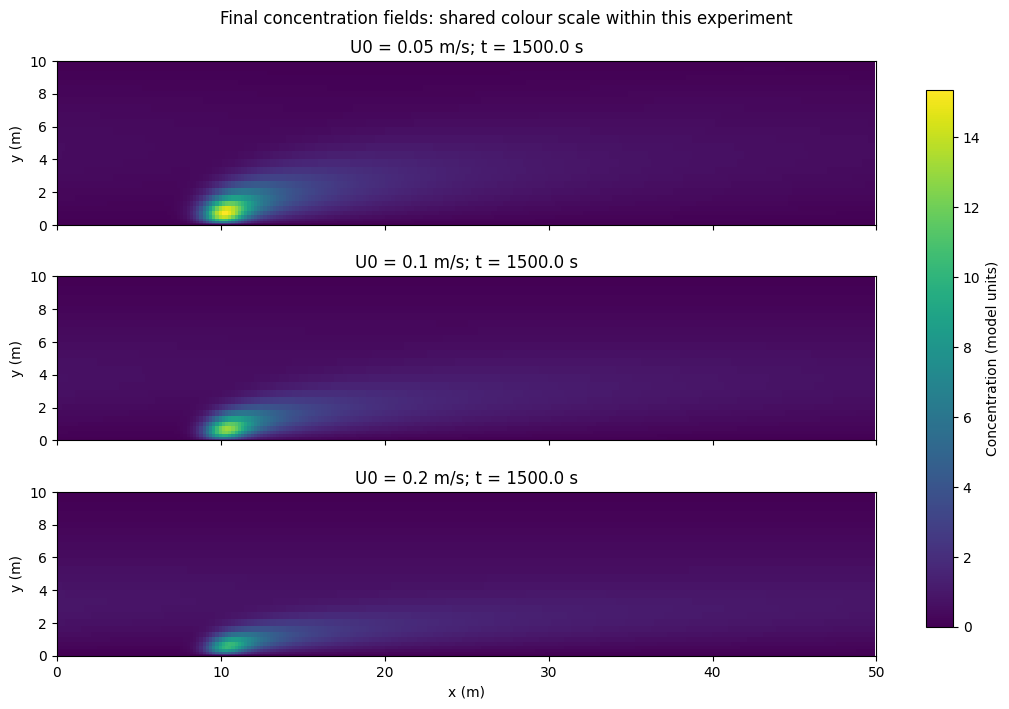

In [16]:
def run_speed(U0):
    kappa = 0.01
    L, w = 50, 10
    Nx, Ny = 256, 32
    S0, S_w, S_x, S_y, S_t = 1, 1, 10, 0, 1
    timestep = (L / Nx) / 0.2
    end_time = 1500
    targets = [(20, 1), (20, 5), (20, 9)]

    coords = dedalus.CartesianCoordinates('x', 'y')
    dist = dedalus.Distributor(coords, dtype=np.float64)
    xb = dedalus.RealFourier(coords['x'], size=Nx,
                              bounds=(0, L), dealias=3/2)
    yb = dedalus.ChebyshevT(coords['y'], size=Ny,
                           bounds=(0, w), dealias=3/2)
    x, y = dist.local_grids(xb, yb)
    ex, ey = coords.unit_vector_fields(dist)
    c = dist.Field(name='c', bases=(xb, yb))
    u = dist.Field(name='u', bases=(xb, yb))
    S = dist.Field(name='S', bases=(xb, yb))
    tau_1 = dist.Field(name='tau_1', bases=xb)
    tau_2 = dist.Field(name='tau_2', bases=xb)
    u['g'] = U0 * (1 - (y - w/2)**2 / (w/2)**2)
    S['g'] = S0 * np.exp(-((x-S_x)**2 + (y-S_y)**2) / S_w**2)
    lift_basis = yb.derivative_basis(1)
    lift = lambda a: dedalus.Lift(a, lift_basis, -1)
    grad_c = dedalus.grad(c) + ey * lift(tau_1)
    dx = lambda a: dedalus.Differentiate(a, coords['x'])

    problem = dedalus.IVP([c, tau_1, tau_2], namespace=locals())
    problem.add_equation('dt(c) + u*dx(c) - kappa*div(grad_c) + lift(tau_2) = S/S_t')
    problem.add_equation('c(y=0) = 0')
    problem.add_equation('c(y=w) = 0')
    solver = problem.build_solver(dedalus.RK222)
    solver.stop_sim_time = end_time
    c['g'] = 0
    c.change_scales(1)

    xx, yy = x.reshape(-1), y.reshape(-1)
    indices = [(np.argmin(abs(xx-a)), np.argmin(abs(yy-b)))
               for a, b in targets]
    actual = [(float(xx[i]), float(yy[j])) for i, j in indices]
    times, values = [0.0], [np.zeros(3)]
    while solver.proceed:
        solver.step(min(timestep, end_time - solver.sim_time))
        if solver.iteration % 10 == 0 or not solver.proceed:
            c.change_scales(1)
            times.append(solver.sim_time)
            values.append([float(c['g'][i, j]) for i, j in indices])
    values = np.array(values)
    if not np.all(np.isfinite(values)):
        raise RuntimeError('Non-finite concentration: inspect this run.')
    c.change_scales(1)
    final_field = np.copy(c['g'])
    if not np.all(np.isfinite(final_field)):
        raise RuntimeError('Non-finite concentration in the final spatial field.')
    return dict(x_grid=np.copy(x).reshape(-1),
                y_grid=np.copy(y).reshape(-1),
                c_final=final_field, snapshot_time=solver.sim_time,
                t=np.array(times), c=values, points=actual)

speed_results = {}
for value in [0.05, 0.1, 0.2]:
    print(f'Running U0 = {value}')
    speed_results[value] = run_speed(value)
print('All three simulations completed.')

fig, axes = plt.subplots(3, 1, figsize=(9, 10),
                         sharex=True, constrained_layout=True)
for value, result in speed_results.items():
    for j, ax in enumerate(axes):
        ax.plot(result['t'], result['c'][:, j], label=f'U0 = {value:g} m/s')
for j, ax in enumerate(axes):
    xp, yp = result['points'][j]
    ax.set(title=f'x = {xp:.2f} m, y = {yp:.2f} m',
           ylabel='Concentration (model units)', xlim=(0,1500))
    ax.grid(alpha=0.25)
    ax.legend()
axes[-1].set_xlabel('Time (s)')
fig.suptitle('Effect of maximum flow speed')
plt.show()

map_items = list(speed_results.items())
map_min = min(0.0, min(float(np.min(r['c_final'])) for _, r in map_items))
map_max = max(float(np.max(r['c_final'])) for _, r in map_items)
if map_max <= map_min:
    map_max = map_min + 1.0

fig_maps, map_axes = plt.subplots(
    len(map_items), 1, figsize=(10, 7),
    sharex=True, sharey=True, constrained_layout=True
)
map_axes = np.atleast_1d(map_axes)
for ax, (parameter, result) in zip(map_axes, map_items):
    mesh = ax.pcolormesh(
        result['x_grid'], result['y_grid'], result['c_final'].T,
        shading='auto', cmap='viridis', vmin=map_min, vmax=map_max
    )
    label = f'U0 = {parameter:g} m/s'
    ax.set(title=f"{label}; t = {result['snapshot_time']:.1f} s",
           ylabel='y (m)', xlim=(0,50), ylim=(0,10))
    ax.set_aspect('equal')
map_axes[-1].set_xlabel('x (m)')
fig_maps.colorbar(mesh, ax=list(map_axes),
                  label='Concentration (model units)', shrink=0.85)
fig_maps.suptitle('Final concentration fields: shared colour scale within this experiment')
plt.show()


### Discussion 1:
The effect of maximum flow speed depends on cross-stream position.
Near the source-side bank, faster flow produces an earlier
concentration rise and higher pollution levels, consistent with
more rapid downstream delivery and less time for diffusive
redistribution before reaching the sampling location. Near the
river centre, slower flow instead produces higher concentrations
at later times, consistent with more time being available for
pollutant to spread across the channel during downstream transport.
These contrasting responses illustrate the competition between
advection and diffusion: faster downstream transport does not
necessarily increase pollution levels farther across the river.

Near the opposite bank, the concentration curves cross, indicating
that the effect of flow speed also depends on observation time.
The periodic streamwise boundary is important because faster flow
allows pollution to circulate through the domain more frequently,
contributing to repeated concentration increases. Increasing
$U_0$ therefore changes both downstream delivery and recirculation,
while the molecular diffusivity remains unchanged. Overall,
higher flow speed redistributes exposure in space and time rather
than uniformly increasing or decreasing concentration throughout
the river.

---

### Exploration 2: Change the diffusivity

Compared to Exploration 1, only diffusivity is varied, using
$\kappa=0.005$, $0.010$, and $0.020\ \mathrm{m^2/s}$.
The maximum flow speed is fixed at $U_0=0.10\ \mathrm{m/s}$,
with the original parabolic velocity profile.
River length ($L=50$ m), width ($w=10$ m), and the continuously
active Gaussian pollution source remain unchanged from Section 2.1.
The same diffusivity acts in both spatial directions.


Running kappa = 0.005


INFO:subsystems:Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 3.0e+00/s


2026-11-12 00:38:15,040 subsystems 0/1 INFO :: Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 3.0e+00/s


INFO:solvers:Simulation stop time reached.


2026-11-12 00:38:18,593 solvers 0/1 INFO :: Simulation stop time reached.


INFO:solvers:Simulation stop time reached.


... (9 outputs left out)

INFO:solvers:Simulation stop time reached.


2026-11-12 00:38:32,343 solvers 0/1 INFO :: Simulation stop time reached.


INFO:solvers:Simulation stop time reached.


2026-11-12 00:38:32,346 solvers 0/1 INFO :: Simulation stop time reached.
All three simulations completed.


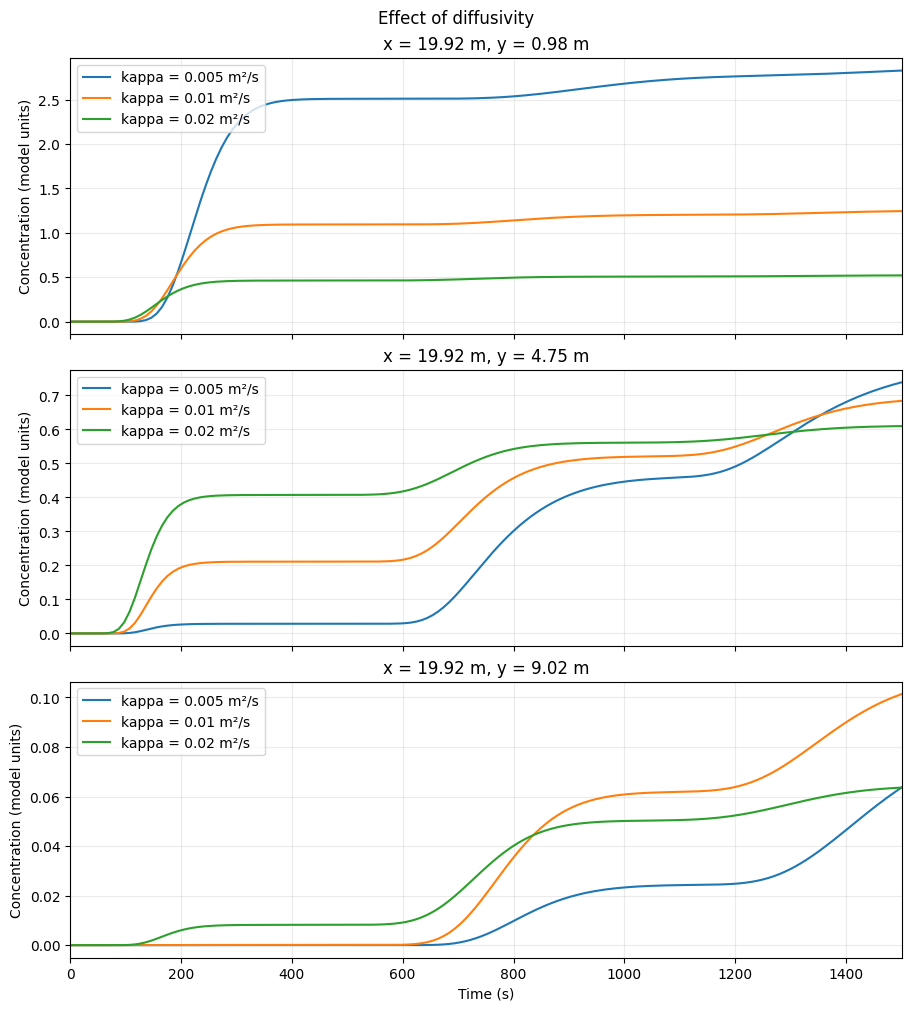

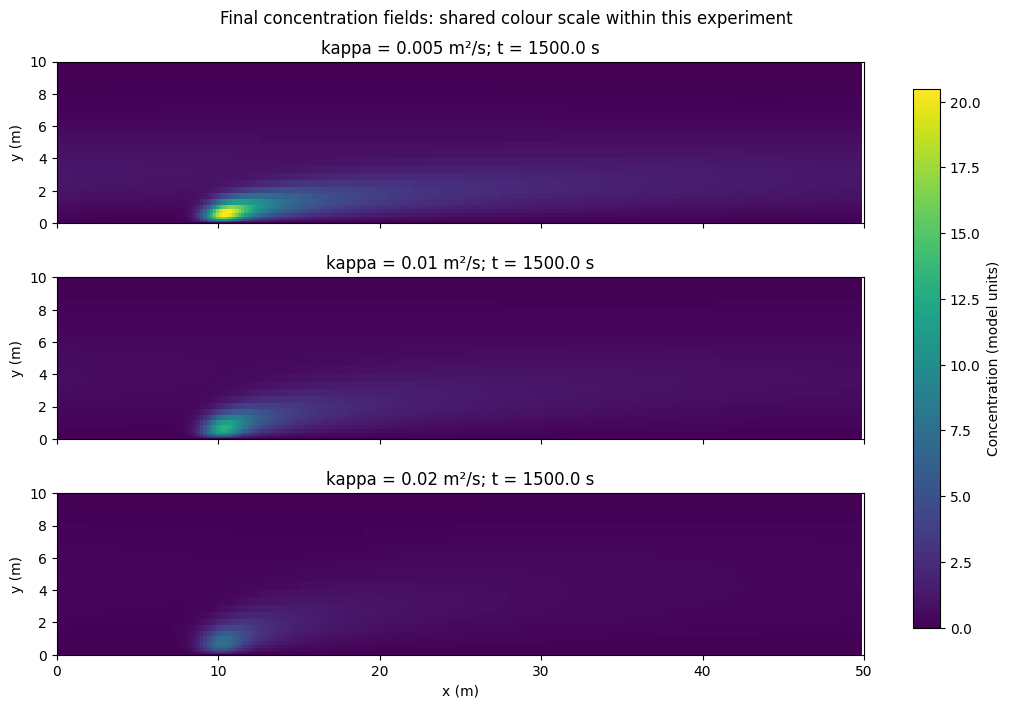

In [19]:
def run_diffusivity(kappa):
    U0 = 0.1
    L, w = 50, 10
    Nx, Ny = 256, 32
    S0, S_w, S_x, S_y, S_t = 1, 1, 10, 0, 1
    timestep = (L / Nx) / 0.2
    end_time = 1500
    targets = [(20, 1), (20, 5), (20, 9)]

    coords = dedalus.CartesianCoordinates('x', 'y')
    dist = dedalus.Distributor(coords, dtype=np.float64)
    xb = dedalus.RealFourier(coords['x'], size=Nx,
                              bounds=(0, L), dealias=3/2)
    yb = dedalus.ChebyshevT(coords['y'], size=Ny,
                           bounds=(0, w), dealias=3/2)
    x, y = dist.local_grids(xb, yb)
    ex, ey = coords.unit_vector_fields(dist)
    c = dist.Field(name='c', bases=(xb, yb))
    u = dist.Field(name='u', bases=(xb, yb))
    S = dist.Field(name='S', bases=(xb, yb))
    tau_1 = dist.Field(name='tau_1', bases=xb)
    tau_2 = dist.Field(name='tau_2', bases=xb)
    u['g'] = U0 * (1 - (y - w/2)**2 / (w/2)**2)
    S['g'] = S0 * np.exp(-((x-S_x)**2 + (y-S_y)**2) / S_w**2)
    lift_basis = yb.derivative_basis(1)
    lift = lambda a: dedalus.Lift(a, lift_basis, -1)
    grad_c = dedalus.grad(c) + ey * lift(tau_1)
    dx = lambda a: dedalus.Differentiate(a, coords['x'])

    problem = dedalus.IVP([c, tau_1, tau_2], namespace=locals())
    problem.add_equation('dt(c) + u*dx(c) - kappa*div(grad_c) + lift(tau_2) = S/S_t')
    problem.add_equation('c(y=0) = 0')
    problem.add_equation('c(y=w) = 0')
    solver = problem.build_solver(dedalus.RK222)
    solver.stop_sim_time = end_time
    c['g'] = 0
    c.change_scales(1)

    xx, yy = x.reshape(-1), y.reshape(-1)
    indices = [(np.argmin(abs(xx-a)), np.argmin(abs(yy-b)))
               for a, b in targets]
    actual = [(float(xx[i]), float(yy[j])) for i, j in indices]
    times, values = [0.0], [np.zeros(3)]
    while solver.proceed:
        solver.step(min(timestep, end_time - solver.sim_time))
        if solver.iteration % 10 == 0 or not solver.proceed:
            c.change_scales(1)
            times.append(solver.sim_time)
            values.append([float(c['g'][i, j]) for i, j in indices])
    values = np.array(values)
    if not np.all(np.isfinite(values)):
        raise RuntimeError('Non-finite concentration: inspect this run.')
    c.change_scales(1)
    final_field = np.copy(c['g'])
    if not np.all(np.isfinite(final_field)):
        raise RuntimeError('Non-finite concentration in the final spatial field.')
    return dict(x_grid=np.copy(x).reshape(-1),
                y_grid=np.copy(y).reshape(-1),
                c_final=final_field, snapshot_time=solver.sim_time,
                t=np.array(times), c=values, points=actual)

diffusion_results = {}
for value in [0.005, 0.01, 0.02]:
    print(f'Running kappa = {value}')
    diffusion_results[value] = run_diffusivity(value)
print('All three simulations completed.')

fig, axes = plt.subplots(3, 1, figsize=(9, 10),
                         sharex=True, constrained_layout=True)
for value, result in diffusion_results.items():
    for j, ax in enumerate(axes):
        ax.plot(result['t'], result['c'][:, j], label=f'kappa = {value:g} m²/s')
for j, ax in enumerate(axes):
    xp, yp = result['points'][j]
    ax.set(title=f'x = {xp:.2f} m, y = {yp:.2f} m',
           ylabel='Concentration (model units)', xlim=(0,1500))
    ax.grid(alpha=0.25)
    ax.legend()
axes[-1].set_xlabel('Time (s)')
fig.suptitle('Effect of diffusivity')
plt.show()

map_items = list(diffusion_results.items())
map_min = min(0.0, min(float(np.min(r['c_final'])) for _, r in map_items))
map_max = max(float(np.max(r['c_final'])) for _, r in map_items)
if map_max <= map_min:
    map_max = map_min + 1.0

fig_maps, map_axes = plt.subplots(
    len(map_items), 1, figsize=(10, 7),
    sharex=True, sharey=True, constrained_layout=True
)
map_axes = np.atleast_1d(map_axes)
for ax, (parameter, result) in zip(map_axes, map_items):
    mesh = ax.pcolormesh(
        result['x_grid'], result['y_grid'], result['c_final'].T,
        shading='auto', cmap='viridis', vmin=map_min, vmax=map_max
    )
    label = f'kappa = {parameter:g} m²/s'
    ax.set(title=f"{label}; t = {result['snapshot_time']:.1f} s",
           ylabel='y (m)', xlim=(0,50), ylim=(0,10))
    ax.set_aspect('equal')
map_axes[-1].set_xlabel('x (m)')
fig_maps.colorbar(mesh, ax=list(map_axes),
                  label='Concentration (model units)', shrink=0.85)
fig_maps.suptitle('Final concentration fields: shared colour scale within this experiment')
plt.show()


### Discussion 2:
Diffusivity influences pollution levels through two competing
processes: it transports pollutant across the river, but also
redistributes concentrated pollution and permits loss through the
zero-concentration banks. Near the source-side bank, increasing
$\kappa$ substantially lowers the later concentration because
pollutant spreads away from the source region more efficiently
and can diffuse towards the absorbing boundary. Further across
the river, the initial effect is different: larger $\kappa$
produces an earlier noticeable concentration increase because
the characteristic diffusion time over a distance $\ell$ scales
as $t_{\mathrm{diff}}\sim\ell^2/\kappa$. Thus, stronger diffusion
reduces local accumulation near the source while initially
increasing exposure at locations farther across the channel.

At later times, faster spreading does not guarantee a higher
concentration at a particular point. The centre-channel curves
eventually reverse their ordering, while near the opposite bank
the intermediate diffusivity produces the highest concentration
at 1500 s. These results are consistent with a balance between
delivery to a location, redistribution away from it, and removal
at the banks: weak diffusion delays cross-stream delivery, whereas
strong diffusion also enhances redistribution and boundary loss.
Because the domain is periodic and the concentrations are still
evolving, this balance depends on both position and observation
time. The results therefore show that increasing diffusivity
accelerates cross-stream transport, but its effect on local
pollution concentration is not universally increasing or decreasing.

---

### Dimensional analysis:
The characteristic time for pollution to diffuse across a river
of width $w$ is estimated by balancing
$c/t_{\mathrm{diff}}\sim\kappa c/w^2$, giving

$$
t_{\mathrm{diff}}\sim\frac{w^2}{\kappa}.
$$

For the baseline parameters, $w=10\ \mathrm{m}$ and
$\kappa=0.01\ \mathrm{m^2/s}$,

$$
t_{\mathrm{diff}}\sim\frac{10^2}{0.01}
=10\,000\ \mathrm{s}\approx2.78\ \mathrm{hours}.
$$

The corresponding estimates for the three diffusivities are:

| Diffusivity $\kappa$ (m²/s) | Diffusion time (s) | Diffusion time (hours) |
|---|---:|---:|
| 0.005 | 20,000 | 5.56 |
| 0.010 | 10,000 | 2.78 |
| 0.020 | 5,000 | 1.39 |

Thus, doubling diffusivity halves the characteristic cross-stream
transport time. This is a characteristic spreading time, not an
exact first-arrival time: small concentrations can occur near
the opposite bank earlier. The bank itself cannot be used as a
concentration-based arrival detector because the model imposes
$c=0$ there.

For an infinitely long river, the corresponding downstream
distance from the source is estimated as

$$
\ell_x\sim U_{\mathrm{char}}t_{\mathrm{diff}}
\sim\frac{U_{\mathrm{char}}w^2}{\kappa}.
$$

Taking the maximum velocity $U_0$ as the characteristic velocity,
the baseline estimate is

$$
\ell_x\sim0.1\times10\,000=1000\ \mathrm{m}.
$$

At fixed diffusivity, increasing $U_0$ increases this distance
without changing the transverse diffusion timescale; at fixed
velocity, increasing $\kappa$ reduces both the diffusion time
and the corresponding downstream distance.

The distance estimate depends on the chosen representative
velocity because the prescribed flow is slower near the banks.
For example, the width-averaged velocity of the parabolic profile is

$$
\overline{u}
=\frac{1}{w}\int_0^w
U_0\left[1-\frac{(y-w/2)^2}{(w/2)^2}\right]\,dy
=\frac{2U_0}{3}.
$$

Using this velocity gives approximately **667 m** for the baseline
case. Both choices indicate a downstream distance of order
$10^3$ m; neither is an exact pollutant trajectory.


---


---

### Turbulent diffusion
In a turbulent flow, tracers will be transported by the turbulent eddies. A common way to model this is to introduce a turbulent diffusivity, $\kappa_T\sim u*l$, where $u$ and $l$ are characteristic velocity and length scales associated with the turbulent eddies.

To explore this effect, create a Dedalus script that includes advection by $u$ and $v$ (the $x$ and $y$ components of the velocity). Then, use the same velocity field as above for $u$ and add to that a fluctuating velocity field that of the form

$$ u=u_0 cos(kx)cos(ky), \quad v=u_0 sin(kx)sin(ky) $$

where $k$ is the wavenumber associated with the velocity fluctuations and $u_0$ is the amplitude of the fluctuations. Note that $k$ should be set to give an integer number of wavelengths in the $x$ and $y$ directions. Vary both $u_0$ and $k$ and study how quicky the tracer is transported across the river. Qualitatively compare this with the expectation based on the hypothesis of turbulent diffusion.

---


### Model and diagnostic

The prescribed cellular velocity is added to the original
parabolic river flow:

$$
u(x,y)=U_0\left[1-\frac{(y-w/2)^2}{(w/2)^2}\right]
+u_0\cos(kx)\cos(ky),
$$

$$
v(x,y)=u_0\sin(kx)\sin(ky).
$$

The concentration equation therefore becomes

$$
\frac{\partial c}{\partial t}
+u\frac{\partial c}{\partial x}
+v\frac{\partial c}{\partial y}
=\kappa\nabla^2c+\frac{S(x,y)}{S_t}.
$$

Choose $k=2\pi n/w$, with integer $n$, giving $n$ wavelengths
across the 10 m river and $5n$ wavelengths along the 50 m domain.
The added velocity is divergence-free and has zero normal
velocity at both banks.

Cross-stream transport is assessed using the streamwise-mean
concentration at the grid point nearest $y=9$ m:

$$
\overline{c}_{\mathrm{near}}(t)
=\frac{1}{L}\int_0^L c(x,y_{\mathrm{near}},t)\,dx.
$$

The same absolute concentration threshold of 0.01 model units
is used in every case. Its first crossing time, interpolated
between saved samples, provides an operational measure of
opposite-bank exposure, rather than an exact first-arrival
time or a direct measurement of turbulent diffusivity.
Cases that do not reach the threshold within 1500 s are
reported as such.

### Exploration 1: change eddy amplitude ($u_0$)
The fluctuation amplitude is varied using
$u_0=0$, $0.01$, and $0.02\ \mathrm{m/s}$, while
$n=1$ and $k=2\pi/10\ \mathrm{m^{-1}}$ remain fixed.
The case $u_0=0$ provides a reference without the added
cellular velocity.

The maximum background flow speed remains
$U_0=0.1\ \mathrm{m/s}$ and diffusivity remains
$\kappa=0.01\ \mathrm{m^2/s}$. Domain dimensions, the continuous
pollution source, and boundary conditions are unchanged.
Each simulation starts from zero concentration and uses
a $256\times32$ grid, a common 0.5 s time step, and a
1500 s duration.

Running u0 = 0.0 m/s, n = 1


INFO:subsystems:Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 5.4e+00/s


2026-11-12 00:39:46,624 subsystems 0/1 INFO :: Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 5.4e+00/s


INFO:solvers:Simulation stop time reached.


2026-11-12 00:39:54,846 solvers 0/1 INFO :: Simulation stop time reached.
Running u0 = 0.01 m/s, n = 1


INFO:subsystems:Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 2.2e+00/s


... (3 outputs left out)

INFO:subsystems:Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 2.1e+00/s


2026-11-12 00:40:22,731 subsystems 0/1 INFO :: Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 2.1e+00/s


INFO:solvers:Simulation stop time reached.


2026-11-12 00:40:51,262 solvers 0/1 INFO :: Simulation stop time reached.
u0 = 0 m/s, n = 1: threshold reached at 533.5 s
u0 = 0.01 m/s, n = 1: threshold reached at 498.7 s
u0 = 0.02 m/s, n = 1: threshold reached at 460.4 s


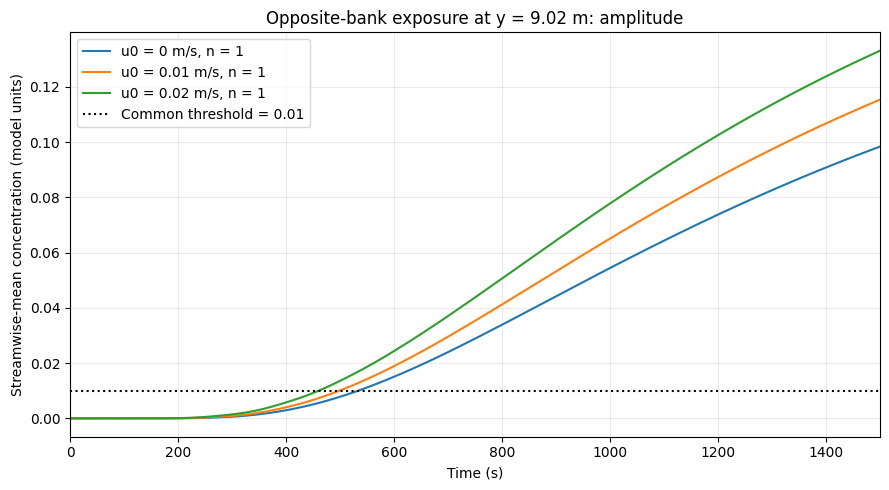

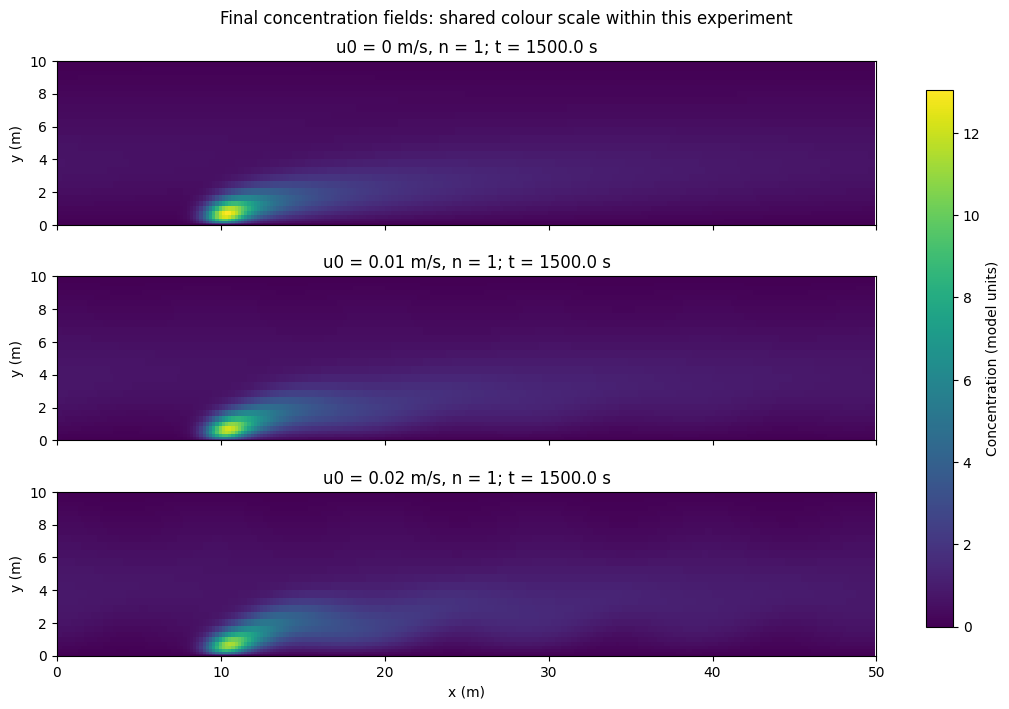

In [20]:
def run_eddies(u0, n):
    U0, kappa = 0.1, 0.01
    L, w = 50, 10
    Nx, Ny = 256, 32
    S0, S_w, S_x, S_y, S_t = 1, 1, 10, 0, 1
    timestep = 0.5
    k_wave = 2 * np.pi * n / w
    end_time = 1500


    coords = dedalus.CartesianCoordinates('x', 'y')
    dist = dedalus.Distributor(coords, dtype=np.float64)
    xb = dedalus.RealFourier(coords['x'], size=Nx,
                              bounds=(0, L), dealias=3/2)
    yb = dedalus.ChebyshevT(coords['y'], size=Ny,
                           bounds=(0, w), dealias=3/2)
    x, y = dist.local_grids(xb, yb)
    ex, ey = coords.unit_vector_fields(dist)
    c = dist.Field(name='c', bases=(xb, yb))
    u = dist.Field(name='u', bases=(xb, yb))
    v = dist.Field(name='v', bases=(xb, yb))
    S = dist.Field(name='S', bases=(xb, yb))
    tau_1 = dist.Field(name='tau_1', bases=xb)
    tau_2 = dist.Field(name='tau_2', bases=xb)
    u['g'] = (U0 * (1 - (y - w/2)**2 / (w/2)**2)
              + u0 * np.cos(k_wave*x) * np.cos(k_wave*y))
    v['g'] = u0 * np.sin(k_wave*x) * np.sin(k_wave*y)
    S['g'] = S0 * np.exp(-((x-S_x)**2 + (y-S_y)**2) / S_w**2)
    lift_basis = yb.derivative_basis(1)
    lift = lambda a: dedalus.Lift(a, lift_basis, -1)
    grad_c = dedalus.grad(c) + ey * lift(tau_1)
    dx = lambda a: dedalus.Differentiate(a, coords['x'])
    dy = lambda a: dedalus.Differentiate(a, coords['y'])

    problem = dedalus.IVP([c, tau_1, tau_2], namespace=locals())
    problem.add_equation('dt(c) + u*dx(c) + v*dy(c) - kappa*div(grad_c) + lift(tau_2) = S/S_t')
    problem.add_equation('c(y=0) = 0')
    problem.add_equation('c(y=w) = 0')
    solver = problem.build_solver(dedalus.RK222)
    solver.stop_sim_time = end_time
    c['g'] = 0
    c.change_scales(1)

    yy = y.reshape(-1)
    iy = np.argmin(abs(yy - 9.0))
    times, values = [0.0], [0.0]
    while solver.proceed:
        solver.step(min(timestep, end_time - solver.sim_time))
        if solver.iteration % 10 == 0 or not solver.proceed:
            c.change_scales(1)
            times.append(solver.sim_time)
            values.append(float(np.mean(c['g'][:, iy])))
    values = np.array(values)
    if not np.all(np.isfinite(values)):
        raise RuntimeError('Non-finite concentration: inspect this run.')
    c.change_scales(1)
    final_field = np.copy(c['g'])
    if not np.all(np.isfinite(final_field)):
        raise RuntimeError('Non-finite concentration in the final spatial field.')
    return dict(x_grid=np.copy(x).reshape(-1),
                y_grid=np.copy(y).reshape(-1),
                c_final=final_field, snapshot_time=solver.sim_time,
                t=np.array(times), c=values, y=float(yy[iy]),
                u0=u0, k_wave=k_wave, n=n)

eddy_amplitude_results = {}
for uamp, number in [(0.0, 1), (0.01, 1), (0.02, 1)]:
    print(f'Running u0 = {uamp} m/s, n = {number}')
    eddy_amplitude_results[(uamp, number)] = run_eddies(uamp, number)

threshold = 0.01
fig, ax = plt.subplots(figsize=(9, 5))
for (uamp, number), result in eddy_amplitude_results.items():
    label = f'u0 = {uamp:g} m/s, n = {number}'
    ax.plot(result['t'], result['c'], label=label)
    hit = np.flatnonzero(result['c'] >= threshold)
    if len(hit):
        j = hit[0]
        if j == 0:
            arrival = result['t'][0]
        else:
            t1, t2 = result['t'][j-1:j+1]
            c1, c2 = result['c'][j-1:j+1]
            arrival = t1 + (threshold-c1)*(t2-t1)/(c2-c1)
        print(f'{label}: threshold reached at {arrival:.1f} s')
    else:
        print(f'{label}: threshold not reached within 1500 s')
ax.axhline(threshold, color='black', linestyle=':',
           label='Common threshold = 0.01')
ax.set(xlabel='Time (s)',
       ylabel='Streamwise-mean concentration (model units)',
       title=f'Opposite-bank exposure at y = {result["y"]:.2f} m: amplitude',
       xlim=(0,1500))
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

map_items = list(eddy_amplitude_results.items())
map_min = min(0.0, min(float(np.min(r['c_final'])) for _, r in map_items))
map_max = max(float(np.max(r['c_final'])) for _, r in map_items)
if map_max <= map_min:
    map_max = map_min + 1.0

fig_maps, map_axes = plt.subplots(
    len(map_items), 1, figsize=(10, 7),
    sharex=True, sharey=True, constrained_layout=True
)
map_axes = np.atleast_1d(map_axes)
for ax, (parameter, result) in zip(map_axes, map_items):
    mesh = ax.pcolormesh(
        result['x_grid'], result['y_grid'], result['c_final'].T,
        shading='auto', cmap='viridis', vmin=map_min, vmax=map_max
    )
    label = f'u0 = {parameter[0]:g} m/s, n = {parameter[1]}'
    ax.set(title=f"{label}; t = {result['snapshot_time']:.1f} s",
           ylabel='y (m)', xlim=(0,50), ylim=(0,10))
    ax.set_aspect('equal')
map_axes[-1].set_xlabel('x (m)')
fig_maps.colorbar(mesh, ax=list(map_axes),
                  label='Concentration (model units)', shrink=0.85)
fig_maps.suptitle('Final concentration fields: shared colour scale within this experiment')
plt.show()


### Discussion 1:
Increasing the fluctuation amplitude causes the concentration near
the opposite bank to rise earlier and reach higher levels over the
simulated period. This indicates that stronger eddies transport
pollutant across the river more effectively, rather than leaving
cross-stream spreading to molecular diffusion alone. The spatial
snapshots show that pollution remains concentrated near the source,
so the enhanced transport does not imply complete mixing across
the channel.

These results qualitatively support the turbulent-diffusion
hypothesis $\kappa_T\sim u_0\ell$. Since the eddy scale is fixed,
increasing $u_0$ is expected to strengthen effective mixing and
shorten the cross-stream transport timescale. The earlier crossing
of the same concentration threshold is consistent with this
expectation. However, this demonstrates a qualitative trend rather
than a measured turbulent diffusivity, because the prescribed
cellular flow is an idealised representation of turbulent motion.

---


### Exploration 2: change the eddy wavenumber ($k$)
The integer $n$ is varied over 1, 2, and 3, with
$k=2\pi n/w$, while the fluctuation amplitude is fixed at
$u_0=0.02\ \mathrm{m/s}$. Increasing $n$ increases the
wavenumber and reduces the spatial scale of the cellular flow.


Running u0 = 0.02 m/s, n = 1


INFO:subsystems:Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 2.0e+00/s


2026-11-12 00:54:19,245 subsystems 0/1 INFO :: Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 2.0e+00/s


INFO:solvers:Simulation stop time reached.


2026-11-12 00:54:47,245 solvers 0/1 INFO :: Simulation stop time reached.
Running u0 = 0.02 m/s, n = 2


INFO:subsystems:Building subproblem matrices 1/1 (~100%) Elapsed: 1s, Remaining: 0s, Rate: 1.6e+00/s


... (3 outputs left out)

INFO:subsystems:Building subproblem matrices 1/1 (~100%) Elapsed: 1s, Remaining: 0s, Rate: 1.4e+00/s


2026-11-12 00:55:18,299 subsystems 0/1 INFO :: Building subproblem matrices 1/1 (~100%) Elapsed: 1s, Remaining: 0s, Rate: 1.4e+00/s


INFO:solvers:Simulation stop time reached.


2026-11-12 00:55:44,051 solvers 0/1 INFO :: Simulation stop time reached.
u0 = 0.02 m/s, n = 1: threshold reached at 460.4 s
u0 = 0.02 m/s, n = 2: threshold reached at 495.0 s
u0 = 0.02 m/s, n = 3: threshold reached at 521.4 s


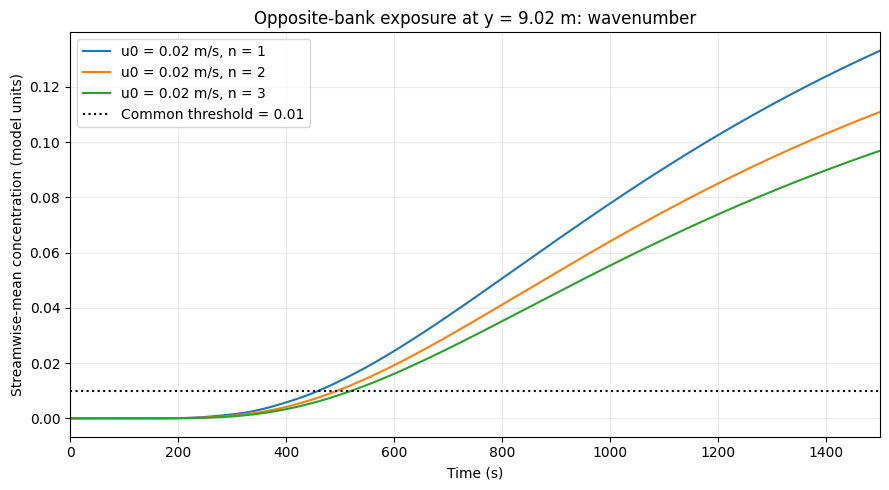

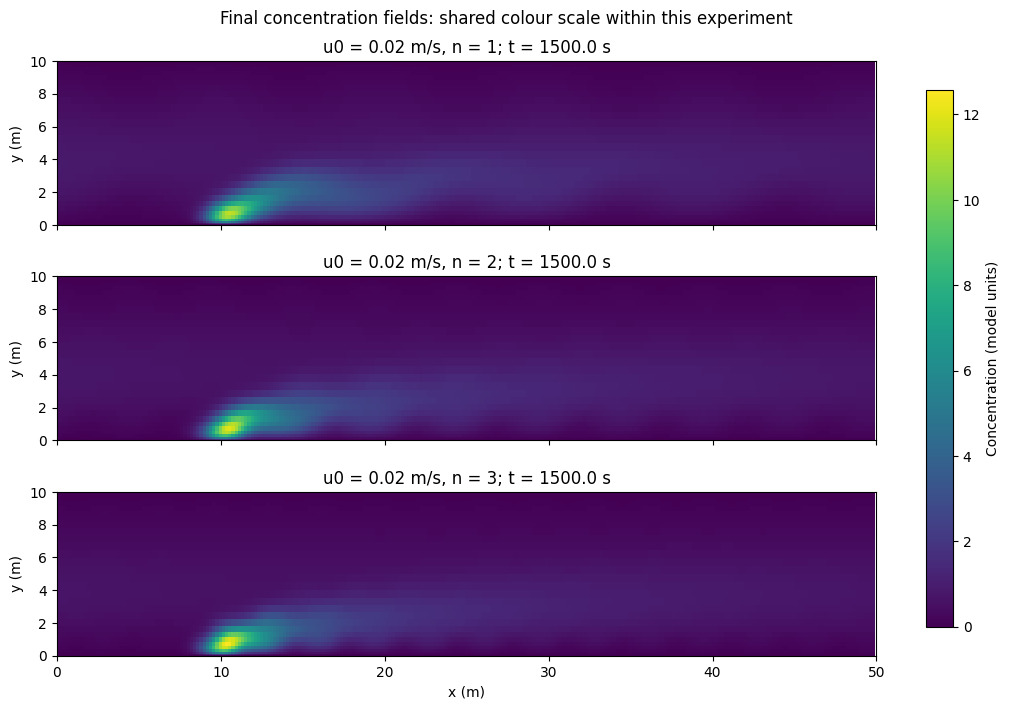

In [21]:
def run_eddies(u0, n):
    U0, kappa = 0.1, 0.01
    L, w = 50, 10
    Nx, Ny = 256, 32
    S0, S_w, S_x, S_y, S_t = 1, 1, 10, 0, 1
    timestep = 0.5
    k_wave = 2 * np.pi * n / w
    end_time = 1500


    coords = dedalus.CartesianCoordinates('x', 'y')
    dist = dedalus.Distributor(coords, dtype=np.float64)
    xb = dedalus.RealFourier(coords['x'], size=Nx,
                              bounds=(0, L), dealias=3/2)
    yb = dedalus.ChebyshevT(coords['y'], size=Ny,
                           bounds=(0, w), dealias=3/2)
    x, y = dist.local_grids(xb, yb)
    ex, ey = coords.unit_vector_fields(dist)
    c = dist.Field(name='c', bases=(xb, yb))
    u = dist.Field(name='u', bases=(xb, yb))
    v = dist.Field(name='v', bases=(xb, yb))
    S = dist.Field(name='S', bases=(xb, yb))
    tau_1 = dist.Field(name='tau_1', bases=xb)
    tau_2 = dist.Field(name='tau_2', bases=xb)
    u['g'] = (U0 * (1 - (y - w/2)**2 / (w/2)**2)
              + u0 * np.cos(k_wave*x) * np.cos(k_wave*y))
    v['g'] = u0 * np.sin(k_wave*x) * np.sin(k_wave*y)
    S['g'] = S0 * np.exp(-((x-S_x)**2 + (y-S_y)**2) / S_w**2)
    lift_basis = yb.derivative_basis(1)
    lift = lambda a: dedalus.Lift(a, lift_basis, -1)
    grad_c = dedalus.grad(c) + ey * lift(tau_1)
    dx = lambda a: dedalus.Differentiate(a, coords['x'])
    dy = lambda a: dedalus.Differentiate(a, coords['y'])

    problem = dedalus.IVP([c, tau_1, tau_2], namespace=locals())
    problem.add_equation('dt(c) + u*dx(c) + v*dy(c) - kappa*div(grad_c) + lift(tau_2) = S/S_t')
    problem.add_equation('c(y=0) = 0')
    problem.add_equation('c(y=w) = 0')
    solver = problem.build_solver(dedalus.RK222)
    solver.stop_sim_time = end_time
    c['g'] = 0
    c.change_scales(1)

    yy = y.reshape(-1)
    iy = np.argmin(abs(yy - 9.0))
    times, values = [0.0], [0.0]
    while solver.proceed:
        solver.step(min(timestep, end_time - solver.sim_time))
        if solver.iteration % 10 == 0 or not solver.proceed:
            c.change_scales(1)
            times.append(solver.sim_time)
            values.append(float(np.mean(c['g'][:, iy])))
    values = np.array(values)
    if not np.all(np.isfinite(values)):
        raise RuntimeError('Non-finite concentration: inspect this run.')
    c.change_scales(1)
    final_field = np.copy(c['g'])
    if not np.all(np.isfinite(final_field)):
        raise RuntimeError('Non-finite concentration in the final spatial field.')
    return dict(x_grid=np.copy(x).reshape(-1),
                y_grid=np.copy(y).reshape(-1),
                c_final=final_field, snapshot_time=solver.sim_time,
                t=np.array(times), c=values, y=float(yy[iy]),
                u0=u0, k_wave=k_wave, n=n)


eddy_wavenumber_results = {}
for uamp, number in [(0.02, 1), (0.02, 2), (0.02, 3)]:
    print(f'Running u0 = {uamp} m/s, n = {number}')
    eddy_wavenumber_results[(uamp, number)] = run_eddies(uamp, number)

threshold = 0.01
fig, ax = plt.subplots(figsize=(9, 5))
for (uamp, number), result in eddy_wavenumber_results.items():
    label = f'u0 = {uamp:g} m/s, n = {number}'
    ax.plot(result['t'], result['c'], label=label)
    hit = np.flatnonzero(result['c'] >= threshold)
    if len(hit):
        j = hit[0]
        if j == 0:
            arrival = result['t'][0]
        else:
            t1, t2 = result['t'][j-1:j+1]
            c1, c2 = result['c'][j-1:j+1]
            arrival = t1 + (threshold-c1)*(t2-t1)/(c2-c1)
        print(f'{label}: threshold reached at {arrival:.1f} s')
    else:
        print(f'{label}: threshold not reached within 1500 s')
ax.axhline(threshold, color='black', linestyle=':',
           label='Common threshold = 0.01')
ax.set(xlabel='Time (s)',
       ylabel='Streamwise-mean concentration (model units)',
       title=f'Opposite-bank exposure at y = {result["y"]:.2f} m: wavenumber',
       xlim=(0,1500))
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

map_items = list(eddy_wavenumber_results.items())
map_min = min(0.0, min(float(np.min(r['c_final'])) for _, r in map_items))
map_max = max(float(np.max(r['c_final'])) for _, r in map_items)
if map_max <= map_min:
    map_max = map_min + 1.0

fig_maps, map_axes = plt.subplots(
    len(map_items), 1, figsize=(10, 7),
    sharex=True, sharey=True, constrained_layout=True
)
map_axes = np.atleast_1d(map_axes)
for ax, (parameter, result) in zip(map_axes, map_items):
    mesh = ax.pcolormesh(
        result['x_grid'], result['y_grid'], result['c_final'].T,
        shading='auto', cmap='viridis', vmin=map_min, vmax=map_max
    )
    label = f'u0 = {parameter[0]:g} m/s, n = {parameter[1]}'
    ax.set(title=f"{label}; t = {result['snapshot_time']:.1f} s",
           ylabel='y (m)', xlim=(0,50), ylim=(0,10))
    ax.set_aspect('equal')
map_axes[-1].set_xlabel('x (m)')
fig_maps.colorbar(mesh, ax=list(map_axes),
                  label='Concentration (model units)', shrink=0.85)
fig_maps.suptitle('Final concentration fields: shared colour scale within this experiment')
plt.show()


### Discussion 2:
At fixed fluctuation amplitude, increasing the wavenumber delays
the crossing of the common concentration threshold and produces
lower concentrations near the opposite bank over the simulated
period. Since a larger wavenumber corresponds to smaller eddies,
these results indicate that larger-scale eddies transport pollutant
across the river more effectively in these experiments. The spatial
snapshots show that pollution remains concentrated near the source
in all cases; the differences in opposite-bank exposure are more
clearly revealed by the concentration histories.

This trend qualitatively agrees with the turbulent-diffusion
hypothesis $\kappa_T\sim u_0\ell$. With $u_0$ fixed and
$\ell\sim1/k$, increasing $k$ reduces the estimated effective
diffusivity and increases the expected cross-stream transport
time. The later threshold crossing for smaller eddies is consistent
with this prediction. However, the results support a qualitative
relationship rather than establish an exact $1/k$ dependence,
because transport in the prescribed cellular flow also depends
on its streamline structure and molecular diffusion.

---

## 3. Optional further investigations

* In the river pollution example, you might notice that the concentration field is mixed more effectively in the x-direction than in the y-direction. The combination of differential advection by the currents and cross-stream diffusion is very effective at mixing the plume in the x-direction. This is an example of Taylor dispersion (Taylor, 1953). Construct numerical experiments to quantify Taylor dispersion and its dependence on the current shear and the diffusivity. You could also separate the diffusivity into parts in the x and y directions with different coefficients.  If you set the x-component of the diffusivity to zero, then any spreading of the concentration in the x-direction should be due to Taylor dispersion.

* Try making the river speed a function of time. The easiest way to do this is to add a new equation so that Dedalus solves for the velocity in addition to the concentration field. For example, you could make the river speed decrease exponentially in time, or it could be sinusoidal in time.

### References

Taylor, G.I., 1953. Dispersion of soluble matter in solvent flowing slowly through a tube. Proceedings of the Royal Society of London. Series A. Mathematical and Physical Sciences, 219(1137), pp.186-203.